# Label-space diffusion for XMC — v3 (LF-AmazonTitles-131K)
**Team TRANSFORMERS · IE 643**

In [ ]:
!find /kaggle/input -path "*run_v3/encoder/config.json"
!ls -la $(dirname $(find /kaggle/input -path "*run_v3/encoder/config.json" | head -1))/.. | head -30

In [1]:
QUICK = False
RUN_ABLATIONS_INFERENCE = True
RUN_ABLATIONS_TRAINING = True
ABLATION_TRAIN_STEPS = 6000
LAUNCH_APP = False
RESUME_FROM = None          # e.g. '/kaggle/input/<this-notebook-output>/run_v3'

import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
!pip install -q faiss-cpu gradio gdown
import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPUs:",
      [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
!mkdir -p /kaggle/working/xmcdiff

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
torch 2.11.0+cu128 | transformers 5.16.1 | GPUs: ['Tesla T4', 'Tesla T4']


In [2]:
%%writefile /kaggle/working/xmcdiff/__init__.py
"""Label-space diffusion for extreme multi-label classification (XMC).

Pipeline
--------
1. Dual encoder: a small sentence encoder is contrastively fine-tuned so that a
   document title lands near the titles of its labels (shared weights).
2. Label bank: one frozen vector per label (text embedding, data centroid, or a
   frequency-adaptive fusion of both). Indexed for nearest-neighbour search.
3. Conditional diffusion: an AdaLN-MLP denoiser learns p(label embedding | doc).
   At inference S samples are drawn with DDIM; each sample is a query into the
   label index, so the samples can cover several label clusters at once.
4. Shortlist + rerank: neighbour hits from all samples are aggregated into a
   shortlist (~200 labels) and a small listwise reranker orders it.

Only the shortlist is ever scored, never the full label vocabulary.
"""

__version__ = "0.1.0"

Writing /kaggle/working/xmcdiff/__init__.py


In [3]:
%%writefile /kaggle/working/xmcdiff/config.py
"""All hyper-parameters in one place. Every stage reads from a Config.

Defaults are the v3 configuration (bge-base encoder, hard negatives, anchored classifiers,
ablation-informed diffusion). V1_OVERRIDES reproduces the first MiniLM run.
"""
from dataclasses import dataclass, asdict, fields
import json


@dataclass
class Config:
    # ---------------- paths / data ----------------
    data_dir: str = "/kaggle/input/lf-amazontitles-131k"
    out_dir: str = "/kaggle/working/run"
    use_content: bool = False        # titles-only dataset -> False
    max_test_docs: int = 0           # >0 -> keep only the first N test docs (quick dry runs)
    val_frac: float = 0.06           # held-out train docs (reranker training + tuning/ablations)
    seed: int = 0
    prop_A: float = 0.6              # Jain et al. 2016 propensity (Amazon sets)
    prop_B: float = 2.6
    device: str = "auto"             # auto | cuda | cpu

    # ---------------- dual encoder ----------------
    encoder_name: str = "BAAI/bge-base-en-v1.5"   # BERT-base architecture, retrieval-pretrained
    pooling: str = "cls"             # cls (bge) | mean (MiniLM)
    max_len: int = 32
    enc_batch: int = 384
    enc_epochs: float = 4.0          # 0 -> use the pretrained encoder frozen
    enc_lr: float = 3e-5
    hn_k: int = 50                   # mine hard negatives from each doc's current top-k labels (0 = off)
    hn_start_epoch: int = 1          # epoch index from which mined negatives are added
    multi_gpu: bool = True           # DataParallel over all visible GPUs (Kaggle T4 x2)
    enc_tau: float = 0.05
    enc_warmup: float = 0.05
    encode_batch: int = 1024

    # ---------------- label space ----------------
    label_mode: str = "centroid"     # text | centroid | fused
    fuse_k: float = 5.0              # alpha_l = k / (k + n_l) weight on text

    # ---------------- diffusion ----------------
    diff_hidden: int = 1024
    diff_blocks: int = 4
    diff_mlp_ratio: int = 2
    cond_mode: str = "concat"        # adaln | concat
    T: int = 1000
    diff_batch: int = 4096
    diff_steps: int = 25000
    diff_lr: float = 3e-4
    diff_warmup: int = 500
    ema: float = 0.999
    lambda_nce: float = 0.2          # 0 -> plain MSE diffusion (ablation)
    nce_tau: float = 0.05
    cfg_drop: float = 0.1            # condition dropout for classifier-free guidance
    beta: float = 1.0                # target sampling prob ~ n_l^-beta (tail reweighting)

    # ---------------- anchored per-label classifiers ----------------
    use_classifier: bool = True
    clf_negs: int = 100              # hard negatives per doc (encoder top-k)
    clf_max_pos: int = 8
    clf_epochs: int = 10
    clf_batch: int = 1024
    clf_lr: float = 2e-3
    clf_reg: float = 1e-3            # shrinkage of delta_l toward 0, x (1 + fuse_k / (n_l + 1))

    # ---------------- sampling / retrieval ----------------
    n_samples: int = 8               # S
    ddim_steps: int = 5
    eta: float = 0.0
    guidance: float = 2.0            # w in x = (1+w) x_cond - w x_uncond
    clamp_sphere: bool = True
    include_doc_query: bool = True   # add the dual-encoder (doc) channel to the shortlist
    doc_budget: float = 0.75         # share of the shortlist reserved for the doc channel
    per_query_k: int = 20
    agg_tau: float = 0.05
    shortlist: int = 300
    index_type: str = "torch"        # torch (exact, GPU) | hnsw | flat (faiss)
    hnsw_M: int = 32
    hnsw_ef: int = 128

    # ---------------- reranker ----------------
    rr_hidden: int = 64
    rr_epochs: int = 40
    rr_lr: float = 3e-3
    tail_tau: float = 0.0            # logit adjustment: score - tau * log(prior)

    # ---------------- evaluation ----------------
    ks: tuple = (1, 3, 5)
    eval_subset: int = 0             # >0 -> evaluate test-split ablations on first N test docs
    ablation_split: str = "val"      # val (held-out half not used by the reranker) | test

    def update(self, **kw):
        names = {f.name for f in fields(self)}
        for k, v in kw.items():
            if k not in names:
                raise KeyError(f"unknown config key: {k}")
            setattr(self, k, v)
        return self

    def to_dict(self):
        d = asdict(self)
        d["ks"] = list(self.ks)
        return d

    def save(self, path):
        with open(path, "w") as f:
            json.dump(self.to_dict(), f, indent=2)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            d = json.load(f)
        names = {f.name for f in fields(cls)}
        d = {k: v for k, v in d.items() if k in names}
        for k, v in LEGACY_DEFAULTS.items():      # older runs predate these fields
            d.setdefault(k, v)
        if "ks" in d:
            d["ks"] = tuple(d["ks"])
        return cls(**d)


def resolve_device(cfg):
    import torch
    if cfg.device == "auto":
        return "cuda" if torch.cuda.is_available() else "cpu"
    return cfg.device


# fields added after v1: values that reproduce v1 behaviour when loading an old config.json
LEGACY_DEFAULTS = dict(pooling="mean", hn_k=0, multi_gpu=False, use_classifier=False, ablation_split="test")

V1_OVERRIDES = dict(encoder_name="sentence-transformers/all-MiniLM-L6-v2", pooling="mean", enc_batch=512,
                    enc_epochs=2.0, enc_lr=5e-5, hn_k=0, val_frac=0.04, label_mode="fused", diff_hidden=768,
                    cond_mode="adaln", diff_steps=20000, beta=0.5, use_classifier=False, n_samples=16,
                    ddim_steps=10, guidance=1.0, shortlist=200, ablation_split="test")

Writing /kaggle/working/xmcdiff/config.py


In [4]:
%%writefile /kaggle/working/xmcdiff/data.py
"""Loading LF-* extreme classification datasets (Extreme Classification Repository).

Supported layouts (auto-detected anywhere under data_dir):
  A) raw JSON lines (official LF-*.raw.zip):
       trn.json.gz / tst.json.gz : {"uid", "title", "content", "target_ind", ...}
       lbl.json.gz               : {"uid", "title", "content"}
  B) plain text + XC sparse label matrices:
       trn_X.txt / tst_X.txt / lbl_X.txt (one text per line, optional "uid->text")
       trn_X_Y.txt / tst_X_Y.txt  (first line "N L", then "lab:val lab:val ...")
Optional: filter_labels_test.txt  ("doc_idx label_idx" reciprocal pairs to mask).
"""
import gzip
import json
import os
import pickle
from dataclasses import dataclass, field

import numpy as np
import scipy.sparse as sp


# --------------------------------------------------------------------------- io
def _open(path):
    if path.endswith(".gz"):
        return gzip.open(path, "rt", encoding="utf-8")
    return open(path, encoding="utf-8", errors="replace")


def _find(data_dir, names):
    for root, _, files in os.walk(data_dir):
        for n in names:
            if n in files:
                return os.path.join(root, n)
    return None


def _read_jsonl(path, use_content, with_labels=True):
    texts, labels = [], []
    with _open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            d = json.loads(line)
            t = (d.get("title") or "").strip()
            if use_content and d.get("content"):
                t = (t + " . " + d["content"]).strip()
            texts.append(t)
            if with_labels:
                labels.append([int(x) for x in d.get("target_ind", [])])
    return texts, labels


def _read_text(path):
    out = []
    with _open(path) as f:
        for line in f:
            line = line.rstrip("\n")
            if "->" in line:
                line = line.split("->", 1)[1]
            out.append(line.strip())
    return out


def _read_xc_sparse(path):
    with _open(path) as f:
        n, L = map(int, f.readline().split()[:2])
        rows, cols = [], []
        for i, line in enumerate(f):
            for tok in line.split():
                j = int(tok.split(":")[0])
                rows.append(i)
                cols.append(j)
    Y = sp.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(n, L))
    return Y


def _lists_to_csr(lists, L):
    indptr = np.zeros(len(lists) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(x) for x in lists])
    indices = np.fromiter((j for x in lists for j in x), dtype=np.int64, count=int(indptr[-1]))
    Y = sp.csr_matrix((np.ones(len(indices), np.float32), indices, indptr), shape=(len(lists), L))
    Y.sum_duplicates()
    Y.data[:] = 1.0
    Y.sort_indices()
    return Y


# ------------------------------------------------------------------- container
@dataclass
class XCData:
    trn_text: list
    tst_text: list
    lbl_text: list
    Y_trn: sp.csr_matrix
    Y_tst: sp.csr_matrix
    filter_tst: np.ndarray = None           # (k, 2) doc_idx, label_idx
    trn_idx: np.ndarray = None              # train docs used for training
    val_idx: np.ndarray = None              # held-out train docs
    freq: np.ndarray = None                 # label counts on trn_idx docs
    inv_prop: np.ndarray = None             # inverse propensity (full train set)
    meta: dict = field(default_factory=dict)

    @property
    def L(self):
        return self.Y_trn.shape[1]


def load_xc(data_dir, use_content=False):
    trn_js = _find(data_dir, ["trn.json.gz", "trn.json"])
    if trn_js:
        tst_js = _find(data_dir, ["tst.json.gz", "tst.json"])
        lbl_js = _find(data_dir, ["lbl.json.gz", "lbl.json"])
        trn_text, trn_lab = _read_jsonl(trn_js, use_content)
        tst_text, tst_lab = _read_jsonl(tst_js, use_content)
        lbl_text, _ = _read_jsonl(lbl_js, use_content, with_labels=False)
        L = len(lbl_text)
        Y_trn, Y_tst = _lists_to_csr(trn_lab, L), _lists_to_csr(tst_lab, L)
        layout = "jsonl"
    else:
        tx = _find(data_dir, ["trn_X.txt", "train.raw.txt", "trn_raw.txt"])
        ts = _find(data_dir, ["tst_X.txt", "test.raw.txt", "tst_raw.txt"])
        lx = _find(data_dir, ["lbl_X.txt", "Y.txt", "label.raw.txt", "lbl_raw.txt"])
        ty = _find(data_dir, ["trn_X_Y.txt"])
        sy = _find(data_dir, ["tst_X_Y.txt"])
        if not all([tx, ts, lx, ty, sy]):
            raise FileNotFoundError(
                f"Could not find dataset files under {data_dir}. Expected trn.json.gz/tst.json.gz/"
                "lbl.json.gz or trn_X.txt/tst_X.txt/lbl_X.txt + trn_X_Y.txt/tst_X_Y.txt")
        trn_text, tst_text, lbl_text = _read_text(tx), _read_text(ts), _read_text(lx)
        Y_trn, Y_tst = _read_xc_sparse(ty), _read_xc_sparse(sy)
        layout = "text"
    filt = None
    fp = _find(data_dir, ["filter_labels_test.txt"])
    if fp:
        arr = np.loadtxt(fp, dtype=np.int64, ndmin=2)
        filt = arr[:, :2] if arr.size else None
    data = XCData(trn_text, tst_text, lbl_text, Y_trn, Y_tst, filt)
    data.meta["layout"] = layout
    return data


def inverse_propensity(Y, A, B):
    """Jain et al. (KDD 2016): 1/p_l = 1 + C (n_l + B)^-A,  C = (log N - 1)(B + 1)^A."""
    N = Y.shape[0]
    n = np.asarray((Y > 0).sum(0)).ravel().astype(np.float64)
    C = (np.log(N) - 1.0) * (B + 1.0) ** A
    return (1.0 + C * np.exp(-A * np.log(n + B))).astype(np.float32)


def prepare(data, val_frac, seed, A, B):
    rng = np.random.default_rng(seed)
    N = data.Y_trn.shape[0]
    perm = rng.permutation(N)
    n_val = int(round(val_frac * N))
    data.val_idx = np.sort(perm[:n_val])
    data.trn_idx = np.sort(perm[n_val:])
    data.freq = np.asarray((data.Y_trn[data.trn_idx] > 0).sum(0)).ravel().astype(np.int64)
    data.inv_prop = inverse_propensity(data.Y_trn, A, B)
    return data


BUCKET_EDGES = [0, 1, 3, 6, 21, np.inf]
BUCKET_NAMES = ["unseen (0)", "1-2", "3-5", "6-20", ">20"]


def label_buckets(freq):
    return np.digitize(freq, BUCKET_EDGES[1:-1], right=False)


def dataset_stats(data):
    Yt, Ys = data.Y_trn, data.Y_tst
    freq_full = np.asarray((Yt > 0).sum(0)).ravel()
    s = {
        "num_labels": int(data.L),
        "num_train_docs": int(Yt.shape[0]),
        "num_train_docs_used": int(len(data.trn_idx)),
        "num_val_docs": int(len(data.val_idx)),
        "num_test_docs": int(Ys.shape[0]),
        "avg_labels_per_train_doc": float(Yt.getnnz(1).mean()),
        "avg_labels_per_test_doc": float(Ys.getnnz(1).mean()),
        "avg_train_docs_per_label": float(freq_full[freq_full > 0].mean()),
        "labels_with_zero_train_docs": int((freq_full == 0).sum()),
        "test_docs_without_labels": int((Ys.getnnz(1) == 0).sum()),
        "median_train_docs_per_label": float(np.median(freq_full)),
        "num_filter_pairs_test": int(0 if data.filter_tst is None else len(data.filter_tst)),
        "layout": data.meta.get("layout"),
    }
    b = label_buckets(data.freq)
    test_pairs_lab = Ys.indices
    s["label_buckets"] = {
        name: {"labels": int((b == i).sum()),
               "test_pairs": int((b[test_pairs_lab] == i).sum())}
        for i, name in enumerate(BUCKET_NAMES)}
    return s


def save_data(data, path):
    with open(path, "wb") as f:
        pickle.dump(data, f, protocol=4)


def load_data(path):
    with open(path, "rb") as f:
        return pickle.load(f)

Writing /kaggle/working/xmcdiff/data.py


In [5]:
%%writefile /kaggle/working/xmcdiff/metrics.py
"""XMC metrics: P@k, nDCG@k, PSP@k, PSnDCG@k, Recall@k, coverage, per-bucket recall.

PSP@k / PSnDCG@k follow pyxclib: the dataset-mean propensity-weighted score is
divided by the dataset-mean score of the ideal (propensity-sorted) ranking.
"""
import numpy as np
import scipy.sparse as sp

from .data import BUCKET_NAMES, label_buckets


def _hits(pred, Y):
    """pred: (N, K) int label ids (-1 = empty). Returns (N, K) float32 hit matrix."""
    Y = Y.tocsr()
    Y.sort_indices()
    N, K = pred.shape
    L = Y.shape[1]
    rows = np.repeat(np.arange(N, dtype=np.int64), np.diff(Y.indptr))
    true_keys = rows * L + Y.indices.astype(np.int64)
    pk = np.arange(N, dtype=np.int64)[:, None] * L + pred.astype(np.int64)
    h = np.isin(pk, true_keys) & (pred >= 0)
    return h.astype(np.float32)


def evaluate(pred, Y, inv_prop, ks=(1, 3, 5), freq=None, extra_k=None):
    """pred: (N, K) ranked label ids; Y: (N, L) csr ground truth."""
    Y = Y.tocsr()
    keep = Y.getnnz(1) > 0
    pred, Y = pred[keep], Y[keep]
    N, K = pred.shape
    kmax = max(max(ks), extra_k or 0)
    if K < kmax:
        pred = np.concatenate([pred, -np.ones((N, kmax - K), dtype=pred.dtype)], 1)
    H = _hits(pred, Y)
    ip = np.asarray(inv_prop, dtype=np.float32)
    ip_pred = np.where(pred >= 0, ip[np.clip(pred, 0, None)], 0.0)
    disc = 1.0 / np.log2(np.arange(kmax) + 2.0)
    n_true = Y.getnnz(1)

    # ideal propensity-weighted rankings per doc
    ideal_ip = np.zeros((N, kmax), dtype=np.float32)
    for i in range(N):
        v = ip[Y.indices[Y.indptr[i]:Y.indptr[i + 1]]]
        v = np.sort(v)[::-1][:kmax]
        ideal_ip[i, :len(v)] = v

    out = {}
    for k in ks:
        idcg = np.cumsum(disc)[np.minimum(n_true, k) - 1]
        out[f"P@{k}"] = float(H[:, :k].sum(1).mean() / k * 100)
        out[f"nDCG@{k}"] = float(((H[:, :k] * disc[:k]).sum(1) / idcg).mean() * 100)
        num = (H[:, :k] * ip_pred[:, :k]).sum(1).mean() / k
        den = ideal_ip[:, :k].sum(1).mean() / k
        out[f"PSP@{k}"] = float(num / den * 100)
        num = ((H[:, :k] * ip_pred[:, :k] * disc[:k]).sum(1) / idcg).mean()
        den = ((ideal_ip[:, :k] * disc[:k]).sum(1) / idcg).mean()
        out[f"PSnDCG@{k}"] = float(num / den * 100)
        out[f"R@{k}"] = float((H[:, :k].sum(1) / n_true).mean() * 100)
    if extra_k:
        out[f"R@{extra_k}"] = float((H[:, :extra_k].sum(1) / n_true).mean() * 100)

    k5 = max(ks)
    correct = pred[:, :k5][H[:, :k5] > 0]
    out[f"coverage@{k5}"] = float(len(np.unique(correct)) / max(1, len(np.unique(Y.indices))) * 100)
    if freq is not None:
        out["bucket_recall@%d" % k5] = bucket_recall(pred[:, :k5], Y, freq)
    out["num_eval_docs"] = int(N)
    return out


def bucket_recall(pred, Y, freq):
    """Recall of gold (doc, label) pairs grouped by the label's training frequency."""
    Y = Y.tocsr()
    N, K = pred.shape
    L = Y.shape[1]
    rows = np.repeat(np.arange(N, dtype=np.int64), np.diff(Y.indptr))
    true_keys = rows * L + Y.indices.astype(np.int64)
    pk = (np.arange(N, dtype=np.int64)[:, None] * L + pred.astype(np.int64))[pred >= 0]
    found = np.isin(true_keys, pk)
    b = label_buckets(freq)[Y.indices]
    res = {}
    for i, name in enumerate(BUCKET_NAMES):
        m = b == i
        res[name] = {"recall": float(found[m].mean() * 100) if m.any() else None,
                     "pairs": int(m.sum())}
    return res


def apply_filter(ids, scores, filt, doc_offset=0):
    """Mask reciprocal (doc, label) pairs. ids/scores: (N, C) numpy arrays."""
    if filt is None or len(filt) == 0:
        return scores
    N = ids.shape[0]
    L = int(max(ids.max(), filt[:, 1].max())) + 1
    fk = filt[:, 0].astype(np.int64) * L + filt[:, 1].astype(np.int64)
    rows = np.arange(doc_offset, doc_offset + N, dtype=np.int64)[:, None]
    m = np.isin(rows * L + ids.astype(np.int64), fk)
    scores = scores.copy()
    scores[m] = -np.inf
    return scores


def topk_from_scores(ids, scores, k):
    order = np.argsort(-scores, axis=1)[:, :k]
    top = np.take_along_axis(ids, order, 1)
    s = np.take_along_axis(scores, order, 1)
    top = np.where(np.isfinite(s), top, -1)
    return top


def format_table(rows, cols=None):
    """rows: {name: metrics dict} -> markdown table."""
    if cols is None:
        cols = ["P@1", "P@3", "P@5", "nDCG@5", "PSP@1", "PSP@3", "PSP@5", "PSnDCG@5", "coverage@5"]
    names = list(rows)
    extra = [c for c in rows[names[0]] if c.startswith("R@") and c not in ("R@1", "R@3", "R@5")]
    cols = cols + extra
    head = "| Method | " + " | ".join(cols) + " |"
    sep = "|---|" + "---|" * len(cols)
    lines = [head, sep]
    for n in names:
        r = rows[n]
        lines.append("| " + n + " | " + " | ".join(
            f"{r[c]:.2f}" if isinstance(r.get(c), (int, float)) else "-" for c in cols) + " |")
    return "\n".join(lines)

Writing /kaggle/working/xmcdiff/metrics.py


In [6]:
%%writefile /kaggle/working/xmcdiff/encoder.py
"""Dual encoder (shared weights) fine-tuned with symmetric InfoNCE + mined hard negatives.

Documents and labels are both short titles, so one encoder embeds both sides.
  * pooling     : "cls" (bge-style models) or "mean" (sentence-transformers MiniLM)
  * negatives   : in-batch labels, plus from epoch `hn_start_epoch` on one mined hard
                  negative per pair (sampled from the doc's current top-`hn_k` labels,
                  excluding its gold labels). Mining is redone before every epoch.
  * false negatives (another column that is also gold for the doc) are masked.
  * multi_gpu   : wraps the encoder in nn.DataParallel when >1 GPU is visible.
"""
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

POOLING_FILE = "xmcdiff_pooling.json"


class TextEncoder(nn.Module):
    def __init__(self, name_or_path, pooling="mean"):
        super().__init__()
        self.model = AutoModel.from_pretrained(name_or_path)
        self.pooling = pooling
        self.amp = False

    def forward(self, input_ids, attention_mask):
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.amp and input_ids.is_cuda):
            out = self.model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        if self.pooling == "cls":
            emb = out[:, 0]
        else:
            m = attention_mask.unsqueeze(-1).to(out.dtype)
            emb = (out * m).sum(1) / m.sum(1).clamp(min=1e-6)
        return F.normalize(emb.float(), dim=-1)

    @property
    def dim(self):
        return self.model.config.hidden_size


def core(enc):
    return enc.module if isinstance(enc, nn.DataParallel) else enc


def maybe_parallel(enc, device, want, log=print):
    """Wrap in DataParallel if requested and >1 GPU; fall back to one GPU if a test forward fails."""
    if not (want and str(device).startswith("cuda") and torch.cuda.device_count() > 1):
        return enc
    try:
        dp = nn.DataParallel(enc)
        with torch.no_grad():
            ids = torch.full((4, 8), 101, dtype=torch.long, device=device)
            dp(ids, torch.ones_like(ids))
        log(f"  [encoder] DataParallel on {torch.cuda.device_count()} GPUs")
        return dp
    except Exception as e:  # pragma: no cover
        log(f"  [encoder] DataParallel failed ({e}); using one GPU")
        return enc


def pretokenize(tok, texts, max_len, batch=20000):
    ids, masks = [], []
    for s in range(0, len(texts), batch):
        enc = tok([t if t else "[empty]" for t in texts[s:s + batch]], padding="max_length",
                  truncation=True, max_length=max_len, return_tensors="np")
        ids.append(enc["input_ids"].astype(np.int32))
        masks.append(enc["attention_mask"].astype(np.int8))
    return np.concatenate(ids), np.concatenate(masks)


def _batch(ids, masks, idx, device):
    m = masks[idx]
    w = max(int(m.sum(1).max()), 1)
    return (torch.from_numpy(ids[idx, :w].astype(np.int64)).to(device),
            torch.from_numpy(m[:, :w].astype(np.int64)).to(device))


def true_pair_keys(Y, L, device):
    """Sorted int64 keys doc*L + label for all gold pairs (for false-negative masks)."""
    Y = Y.tocsr()
    rows = np.repeat(np.arange(Y.shape[0], dtype=np.int64), np.diff(Y.indptr))
    keys = np.sort(rows * L + Y.indices.astype(np.int64))
    return torch.from_numpy(keys).to(device)


def is_true_pair(sorted_keys, doc, lab, L):
    """doc: (B,), lab: (M,) -> (B, M) bool, True where (doc_i, lab_j) is a gold pair."""
    q = doc[:, None] * L + lab[None, :]
    pos = torch.searchsorted(sorted_keys, q.reshape(-1)).clamp(max=sorted_keys.numel() - 1)
    return (sorted_keys[pos] == q.reshape(-1)).view(q.shape)


def is_true_pair_elem(sorted_keys, doc, lab, L):
    """Elementwise version: doc and lab broadcastable -> bool of the broadcast shape."""
    q = doc * L + lab
    pos = torch.searchsorted(sorted_keys, q.reshape(-1)).clamp(max=sorted_keys.numel() - 1)
    return (sorted_keys[pos] == q.reshape(-1)).view(q.shape)


@torch.no_grad()
def topk_labels(H, E, k, device, rows=2048):
    """Exact top-k labels by inner product. H: (n, d), E: (L, d) numpy/torch -> (n, k) int64 torch on device."""
    Ht = torch.as_tensor(H, device=device)
    Et = torch.as_tensor(E, device=device)
    dt = torch.float16 if str(device).startswith("cuda") else torch.float32
    Ht, Et = Ht.to(dt), Et.to(dt)
    rows = max(1, min(rows, int(2 ** 28 // Et.shape[0])))
    out = []
    for s in range(0, Ht.shape[0], rows):
        out.append((Ht[s:s + rows] @ Et.T).topk(k, dim=1).indices)
    return torch.cat(out)


def train_dual_encoder(cfg, doc_tok, lbl_tok, Y_trn, device, log=print):
    """doc_tok/lbl_tok: (ids, masks) numpy; Y_trn: csr (n_train_docs x L), rows aligned with doc_tok."""
    tok = AutoTokenizer.from_pretrained(cfg.encoder_name)
    enc = TextEncoder(cfg.encoder_name, cfg.pooling).to(device)
    enc.amp = str(device).startswith("cuda")
    if cfg.enc_epochs <= 0:
        return enc, tok, []
    run = maybe_parallel(enc, device, cfg.multi_gpu, log)
    L = Y_trn.shape[1]
    Y = Y_trn.tocoo()
    pairs = np.stack([Y.row, Y.col], 1).astype(np.int64)
    keys = true_pair_keys(Y_trn, L, device)
    B = min(cfg.enc_batch, len(pairs))
    steps_per_epoch = max(1, len(pairs) // B)
    total = max(1, int(cfg.enc_epochs * steps_per_epoch))
    warm = max(1, int(cfg.enc_warmup * total))
    opt = torch.optim.AdamW(enc.parameters(), lr=cfg.enc_lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * max(0.0, (total - s) / max(1, total - warm)))
    use_amp = str(device).startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    rng = np.random.default_rng(cfg.seed)
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    hist, t0, step, epoch = [], time.time(), 0, 0
    hn = None
    while step < total:
        if cfg.hn_k > 0 and epoch >= cfg.hn_start_epoch:
            tm = time.time()
            Hd = encode(run, *doc_tok, device, cfg.encode_batch)
            El = encode(run, *lbl_tok, device, cfg.encode_batch)
            hn = topk_labels(Hd, El, cfg.hn_k, device)
            del Hd, El
            log(f"  [encoder] mined top-{cfg.hn_k} hard negatives for epoch {epoch + 1} in {time.time() - tm:.0f}s")
        run.train()
        perm = rng.permutation(len(pairs))
        for s in range(steps_per_epoch):
            if step >= total:
                break
            p = pairs[perm[s * B:(s + 1) * B]]
            dt = torch.from_numpy(p[:, 0]).to(device)
            lt = torch.from_numpy(p[:, 1]).to(device)
            lab_idx = p[:, 1]
            if hn is not None:
                cols = torch.randint(0, hn.shape[1], (len(p), 4), device=device, generator=gen)
                cand = hn[dt][torch.arange(len(p), device=device)[:, None], cols]       # (b, 4)
                bad = is_true_pair_elem(keys, dt[:, None], cand, L)
                first = (~bad).float().argmax(1)
                neg = cand[torch.arange(len(p), device=device), first]
                allbad = bad.all(1)
                neg = torch.where(allbad, torch.randint(0, L, (len(p),), device=device, generator=gen), neg)
                lab_idx = np.concatenate([p[:, 1], neg.cpu().numpy()])
            d_ids, d_m = _batch(*doc_tok, p[:, 0], device)
            l_ids, l_m = _batch(*lbl_tok, lab_idx, device)
            q = run(d_ids, d_m)
            k = run(l_ids, l_m)
            logits = (q.float() @ k.float().T) / cfg.enc_tau                         # (b, b or 2b)
            lt_all = torch.from_numpy(lab_idx).to(device)
            fn = is_true_pair(keys, dt, lt_all, L)
            own = torch.zeros_like(fn)
            own[torch.arange(len(p)), torch.arange(len(p))] = True
            logits = logits.masked_fill(fn & ~own, float("-inf"))
            tgt = torch.arange(len(p), device=device)
            loss = 0.5 * (F.cross_entropy(logits, tgt) + F.cross_entropy(logits[:, :len(p)].T, tgt))
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(enc.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            hist.append(loss.item())
            step += 1
            if step % 100 == 0 or step == total:
                log(f"  [encoder] step {step}/{total} (epoch {epoch + 1})  loss {np.mean(hist[-100:]):.4f}  "
                    f"{time.time() - t0:.0f}s")
        epoch += 1
    enc.eval()
    return enc, tok, hist


@torch.no_grad()
def encode(enc, ids, masks, device, batch=1024):
    enc.eval()
    c = core(enc)
    c.amp = str(device).startswith("cuda")
    out = np.zeros((len(ids), c.dim), dtype=np.float16)
    order = np.argsort(-masks.sum(1), kind="stable")   # length-sorted batches -> less padding
    for s in range(0, len(ids), batch):
        idx = order[s:s + batch]
        i, m = _batch(ids, masks, idx, device)
        out[idx] = enc(i, m).float().cpu().numpy().astype(np.float16)
    return out


def save_encoder(enc, tok, path):
    c = core(enc)
    os.makedirs(path, exist_ok=True)
    c.model.save_pretrained(path)
    tok.save_pretrained(path)
    json.dump({"pooling": c.pooling}, open(os.path.join(path, POOLING_FILE), "w"))


def load_encoder(path, device, pooling=None):
    if pooling is None:
        pf = os.path.join(path, POOLING_FILE)
        pooling = json.load(open(pf))["pooling"] if os.path.exists(pf) else "mean"
    tok = AutoTokenizer.from_pretrained(path)
    enc = TextEncoder(path, pooling).to(device).eval()
    enc.amp = str(device).startswith("cuda")
    return enc, tok


@torch.no_grad()
def encode_texts(enc, tok, texts, max_len, device, batch=256):
    ids, m = pretokenize(tok, texts, max_len)
    return encode(enc, ids, m, device, batch).astype(np.float32)

Writing /kaggle/working/xmcdiff/encoder.py


In [7]:
%%writefile /kaggle/working/xmcdiff/label_space.py
"""Label bank: one frozen, L2-normalised vector per label.

modes
  text     : encoder embedding of the label title (works for unseen labels)
  centroid : mean embedding of the label's training documents (text fallback if unseen)
  fused    : alpha_l * text + (1 - alpha_l) * centroid, alpha_l = k / (k + n_l)
             -> rare labels lean on their text, frequent labels on their data
"""
import numpy as np
import scipy.sparse as sp


def _norm(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.maximum(n, 1e-8)


def build_label_bank(T_lbl, H_trn, Y_trn, mode="fused", fuse_k=5.0):
    """T_lbl: (L, d) label text emb; H_trn: (n, d) train doc emb; Y_trn: (n, L) csr."""
    T_lbl = _norm(T_lbl.astype(np.float32))
    if mode == "text":
        return T_lbl
    Y = sp.csr_matrix(Y_trn, dtype=np.float32)
    n = np.asarray(Y.sum(0)).ravel()
    C = np.asarray(Y.T @ H_trn.astype(np.float32))
    C = _norm(C)
    seen = n > 0
    if mode == "centroid":
        E = np.where(seen[:, None], C, T_lbl)
        return _norm(E).astype(np.float32)
    if mode == "fused":
        a = (fuse_k / (fuse_k + n))[:, None].astype(np.float32)
        E = a * T_lbl + (1 - a) * np.where(seen[:, None], C, T_lbl)
        return _norm(E).astype(np.float32)
    raise ValueError(mode)

Writing /kaggle/working/xmcdiff/label_space.py


In [8]:
%%writefile /kaggle/working/xmcdiff/classifier.py
"""Anchored per-label classifiers on top of the frozen encoder.

Each label l gets a weight vector w_l = e_l + delta_l, where e_l is its (frozen) label-bank
vector and delta_l starts at zero. Score:

    s(x, l) = exp(log_scale) * (h_x . w_l - shift) + b_l

Training: one-vs-all BCE over each training doc's gold labels plus `clf_negs` hard negatives
(the doc's top labels under the frozen dual encoder). delta_l is shrunk toward 0 with weight
clf_reg * (1 + fuse_k / (n_l + 1)), so labels with few training docs stay close to their
embedding (they cannot overfit), and never-seen labels score exactly like the dual encoder.
Only rows touched in a batch are updated (sparse embeddings + SparseAdam).
"""
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .encoder import is_true_pair_elem, topk_labels, true_pair_keys


class AnchoredClassifier(nn.Module):
    def __init__(self, E, init_scale=20.0, init_shift=0.6):
        super().__init__()
        E = torch.as_tensor(E, dtype=torch.float32)
        L, d = E.shape
        self.register_buffer("E", E)
        self.delta = nn.Embedding(L, d, sparse=True)
        self.bias = nn.Embedding(L, 1, sparse=True)
        nn.init.zeros_(self.delta.weight)
        nn.init.zeros_(self.bias.weight)
        self.log_scale = nn.Parameter(torch.tensor(math.log(init_scale)))
        self.shift = nn.Parameter(torch.tensor(init_shift))

    def forward(self, H, ids):
        w = self.E[ids] + self.delta(ids)                               # (B, C, d)
        s = torch.einsum("bcd,bd->bc", w, H)
        return self.log_scale.exp() * (s - self.shift) + self.bias(ids).squeeze(-1)

    @torch.no_grad()
    def score(self, H, ids, chunk=256):
        """Device-agnostic inference: inputs may live anywhere; output returned on H's device."""
        dev = self.E.device
        out = []
        for s in range(0, ids.shape[0], chunk):
            out.append(self(H[s:s + chunk].to(dev).float(), ids[s:s + chunk].to(dev).long()))
        return torch.cat(out).to(H.device)


def _pos_matrix(Y, P):
    Y = Y.tocsr()
    n = Y.shape[0]
    pos = -np.ones((n, P), dtype=np.int64)
    for i in range(n):
        r = Y.indices[Y.indptr[i]:Y.indptr[i + 1]]
        if len(r) > P:
            r = np.random.default_rng(i).choice(r, P, replace=False)
        pos[i, :len(r)] = r
    return pos


def train_classifier(cfg, H, E, Y, freq, device, log=print):
    """H: (n, d) frozen train-doc embeddings; E: (L, d) label bank; Y: (n, L) csr; freq: (L,)."""
    torch.manual_seed(cfg.seed)
    n, L = Y.shape
    t0 = time.time()
    Ht = torch.as_tensor(np.asarray(H, dtype=np.float32), device=device)
    neg = topk_labels(Ht, torch.as_tensor(E, dtype=torch.float32, device=device), cfg.clf_negs, device)
    log(f"  [classifier] mined {cfg.clf_negs} negatives/doc in {time.time() - t0:.0f}s")
    pos = torch.as_tensor(_pos_matrix(Y, cfg.clf_max_pos), device=device)
    keys = true_pair_keys(Y, L, device)
    lam = torch.as_tensor(cfg.clf_reg * (1.0 + cfg.fuse_k / (np.asarray(freq, dtype=np.float32) + 1.0)),
                          device=device)
    model = AnchoredClassifier(E).to(device)
    sp_opt = torch.optim.SparseAdam(list(model.delta.parameters()) + list(model.bias.parameters()), lr=cfg.clf_lr)
    dn_opt = torch.optim.Adam([model.log_scale, model.shift], lr=1e-2)
    B = min(cfg.clf_batch, n)
    hist = []
    for ep in range(cfg.clf_epochs):
        perm = torch.randperm(n, device=device)
        tot, cnt = 0.0, 0
        for s in range(0, n, B):
            i = perm[s:s + B]
            p, ng = pos[i], neg[i]
            ng_bad = is_true_pair_elem(keys, i[:, None], ng, L)        # mined "negatives" that are gold
            ids = torch.cat([p.clamp(min=0), ng], 1)
            y = torch.cat([torch.ones_like(p, dtype=torch.float32), torch.zeros_like(ng, dtype=torch.float32)], 1)
            valid = torch.cat([p >= 0, ~ng_bad], 1)
            logit = model(Ht[i], ids)
            bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
            loss = (bce * valid).sum(1).div(valid.sum(1).clamp(min=1)).mean()
            d = model.delta(ids)
            reg = (lam[ids] * d.pow(2).sum(-1) * valid).sum() / valid.sum().clamp(min=1)
            sp_opt.zero_grad()
            dn_opt.zero_grad()
            (loss + reg).backward()
            sp_opt.step()
            dn_opt.step()
            tot += loss.item() * len(i)
            cnt += len(i)
        hist.append(tot / cnt)
        log(f"  [classifier] epoch {ep + 1}/{cfg.clf_epochs}  bce {hist[-1]:.4f}  "
            f"scale {model.log_scale.exp().item():.1f}  shift {model.shift.item():.3f}  {time.time() - t0:.0f}s")
    return model.eval(), hist


def save_classifier(model, hist, path):
    torch.save({"delta": model.delta.weight.detach().half().cpu(), "bias": model.bias.weight.detach().cpu(),
                "log_scale": model.log_scale.detach().cpu(), "shift": model.shift.detach().cpu(),
                "hist": hist}, path)


def load_classifier(path, E, device):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = AnchoredClassifier(E)
    with torch.no_grad():
        m.delta.weight.copy_(ck["delta"].float())
        m.bias.weight.copy_(ck["bias"])
        m.log_scale.copy_(ck["log_scale"])
        m.shift.copy_(ck["shift"])
    return m.to(device).eval()

Writing /kaggle/working/xmcdiff/classifier.py


In [9]:
%%writefile /kaggle/working/xmcdiff/diffusion.py
"""Conditional Gaussian diffusion in the label-embedding space.

x0      : sqrt(d) * e_label  (unit-norm label vector scaled to ~unit per-dim variance)
cond    : document embedding h (from the dual encoder)
network : AdaLN residual MLP predicting x0 directly (x0-parameterisation)
loss    : MSE(x0_hat, x0) + lambda * InfoNCE(x0_hat vs in-batch label vectors)
          The InfoNCE "anchor" pulls predictions onto real label vectors instead of
          the space between them (the rounding problem of embedding diffusion). It is
          weighted by alpha_bar_t, so it acts near t=0 and leaves high-noise steps to
          model the full multi-modal conditional.
CFG     : the condition is replaced by a learned null vector with prob cfg_drop.
sampling: DDIM with optional sphere clamp of x0_hat and classifier-free guidance.
"""
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .encoder import is_true_pair, true_pair_keys


def cosine_alpha_bar(T, s=0.008):
    x = torch.linspace(0, T, T + 1, dtype=torch.float64)
    ac = torch.cos(((x / T) + s) / (1 + s) * math.pi / 2) ** 2
    ac = ac / ac[0]
    betas = (1 - ac[1:] / ac[:-1]).clamp(0, 0.999)
    return torch.cumprod(1 - betas, 0).float()          # (T,)


def timestep_embedding(t, dim=256, max_period=10000):
    half = dim // 2
    freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=t.device).float() / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([torch.cos(a), torch.sin(a)], -1)


class AdaLNBlock(nn.Module):
    def __init__(self, h, ratio):
        super().__init__()
        self.ln = nn.LayerNorm(h, elementwise_affine=False)
        self.mlp = nn.Sequential(nn.Linear(h, h * ratio), nn.GELU(), nn.Linear(h * ratio, h))
        self.mod = nn.Linear(h, 3 * h)
        nn.init.zeros_(self.mod.weight)
        nn.init.zeros_(self.mod.bias)

    def forward(self, x, c):
        shift, scale, gate = self.mod(c).chunk(3, -1)
        return x + gate * self.mlp(self.ln(x) * (1 + scale) + shift)


class Denoiser(nn.Module):
    def __init__(self, d, cond_dim, hidden=768, blocks=4, ratio=2, cond_mode="adaln"):
        super().__init__()
        self.d, self.cond_dim, self.cond_mode = d, cond_dim, cond_mode
        in_dim = d + (cond_dim if cond_mode == "concat" else 0)
        self.inp = nn.Linear(in_dim, hidden)
        self.t_mlp = nn.Sequential(nn.Linear(256, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.c_mlp = nn.Sequential(nn.Linear(cond_dim, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.null = nn.Parameter(torch.zeros(cond_dim))
        self.blocks = nn.ModuleList([AdaLNBlock(hidden, ratio) for _ in range(blocks)])
        self.out_ln = nn.LayerNorm(hidden)
        self.out = nn.Linear(hidden, d)

    def forward(self, z, t, h, drop=None):
        if drop is not None:
            h = torch.where(drop[:, None], self.null.to(h.dtype).expand_as(h), h)
        x = self.inp(torch.cat([z, h], -1) if self.cond_mode == "concat" else z)
        c = self.t_mlp(timestep_embedding(t))
        if self.cond_mode == "adaln":
            c = c + self.c_mlp(h)
        c = F.silu(c)
        for b in self.blocks:
            x = b(x, c)
        return self.out(self.out_ln(x))


def build_model(cfg, d, cond_dim):
    return Denoiser(d, cond_dim, cfg.diff_hidden, cfg.diff_blocks, cfg.diff_mlp_ratio, cfg.cond_mode)


def train_diffusion(cfg, H, E, Y, freq, device, log=print):
    """H: (n, dc) train-doc embeddings; E: (L, d) label bank; Y: (n, L) csr gold pairs."""
    torch.manual_seed(cfg.seed)
    n, L = Y.shape
    d = E.shape[1]
    Yc = Y.tocoo()
    pdoc = torch.from_numpy(Yc.row.astype(np.int64)).to(device)
    plab = torch.from_numpy(Yc.col.astype(np.int64)).to(device)
    w = torch.from_numpy(np.maximum(freq[Yc.col], 1).astype(np.float64) ** (-cfg.beta)).float().to(device)
    keys = true_pair_keys(Y, L, device)
    Ht = torch.from_numpy(np.asarray(H, dtype=np.float32)).to(device)
    Et = torch.from_numpy(np.asarray(E, dtype=np.float32)).to(device)
    ab = cosine_alpha_bar(cfg.T).to(device)
    model = build_model(cfg, d, Ht.shape[1]).to(device)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.diff_lr, weight_decay=0.0)
    total, warm = cfg.diff_steps, cfg.diff_warmup
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total)))))
    use_amp = device.startswith("cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    B = min(cfg.diff_batch, len(pdoc))
    sq = math.sqrt(d)
    hist = {"loss": [], "mse": [], "nce": []}
    t0 = time.time()
    model.train()
    for step in range(total):
        pi = torch.multinomial(w, B, replacement=True)
        doc, lab = pdoc[pi], plab[pi]
        x0 = Et[lab] * sq
        t = torch.randint(0, cfg.T, (B,), device=device)
        noise = torch.randn_like(x0)
        a = ab[t][:, None]
        zt = a.sqrt() * x0 + (1 - a).sqrt() * noise
        drop = torch.rand(B, device=device) < cfg.cfg_drop
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            x0_hat = model(zt, t, Ht[doc], drop).float()
        mse = F.mse_loss(x0_hat, x0)
        loss = mse
        nce = torch.zeros((), device=device)
        if cfg.lambda_nce > 0:
            keep = ~drop
            q = F.normalize(x0_hat[keep], dim=-1)
            k = Et[lab]
            logits = q @ k.T / cfg.nce_tau
            fn = is_true_pair(keys, doc[keep], lab, L)
            own = torch.zeros_like(fn)
            own[torch.arange(fn.shape[0], device=device), torch.nonzero(keep).squeeze(1)] = True
            logits = logits.masked_fill(fn & ~own, float("-inf"))
            ce = F.cross_entropy(logits, torch.nonzero(keep).squeeze(1), reduction="none")
            # weight by signal level alpha_bar_t: snap onto a label near t=0, leave the
            # high-noise steps free to model the full (multi-modal) conditional
            wt = a.squeeze(1)[keep]
            nce = (ce * wt).sum() / wt.sum().clamp(min=1e-6)
            loss = mse + cfg.lambda_nce * nce
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        with torch.no_grad():
            dec = min(cfg.ema, (1 + step) / (10 + step))
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.mul_(dec).add_(pm.detach(), alpha=1 - dec)
        hist["loss"].append(loss.item())
        hist["mse"].append(mse.item())
        hist["nce"].append(nce.item())
        if (step + 1) % 500 == 0 or step + 1 == total:
            log(f"  [diffusion] step {step + 1}/{total}  loss {np.mean(hist['loss'][-500:]):.4f}  "
                f"mse {np.mean(hist['mse'][-500:]):.4f}  nce {np.mean(hist['nce'][-500:]):.4f}  "
                f"{time.time() - t0:.0f}s")
    return ema, hist


@torch.no_grad()
def ddim_sample(model, H, n_samples, steps, T, eta=0.0, guidance=0.0, clamp=True, generator=None):
    """H: (B, dc) torch tensor on model device. Returns (B, S, d) unit-norm samples."""
    device = H.device
    B, S, d = H.shape[0], n_samples, model.d
    ab = cosine_alpha_bar(T).to(device)
    Hs = H.repeat_interleave(S, 0)
    z = torch.randn(B * S, d, device=device, generator=generator)
    ts = torch.linspace(T - 1, 0, steps, device=device).round().long()
    sq = math.sqrt(d)
    use_amp = device.type == "cuda"
    x0 = z
    for i, t in enumerate(ts):
        tt = t.expand(B * S)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            if guidance != 0:
                both = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([Hs, Hs]),
                             torch.cat([torch.zeros(B * S, dtype=torch.bool, device=device),
                                        torch.ones(B * S, dtype=torch.bool, device=device)]))
                xc, xu = both.float().chunk(2)
                x0 = (1 + guidance) * xc - guidance * xu
            else:
                x0 = model(z, tt, Hs).float()
        if clamp:
            x0 = F.normalize(x0, dim=-1) * sq
        if i == len(ts) - 1:
            break
        tp = ts[i + 1]
        a_t, a_p = ab[t], ab[tp]
        eps = (z - a_t.sqrt() * x0) / (1 - a_t).sqrt()
        sigma = eta * ((1 - a_p) / (1 - a_t) * (1 - a_t / a_p)).clamp(min=0).sqrt()
        z = a_p.sqrt() * x0 + (1 - a_p - sigma ** 2).clamp(min=0).sqrt() * eps
        if eta > 0:
            z = z + sigma * torch.randn(z.shape, device=device, generator=generator)
    return F.normalize(x0, dim=-1).view(B, S, d)


def save_diffusion(model, cfg, hist, path):
    torch.save({"state": model.state_dict(), "d": model.d, "cond_dim": model.cond_dim,
                "cfg": cfg.to_dict(), "hist": hist}, path)


def load_diffusion(path, cfg, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = build_model(cfg, ck["d"], ck["cond_dim"]).to(device)
    m.load_state_dict(ck["state"])
    return m.eval(), ck.get("hist")

Writing /kaggle/working/xmcdiff/diffusion.py


In [10]:
%%writefile /kaggle/working/xmcdiff/retrieval.py
"""Label index (exact GPU matmul or FAISS) and two-channel shortlist construction.

Sample channel : each of the S diffusion samples retrieves its top-m labels; a
                 label's vote is sum_s exp((cos_s - 1) / tau).
Doc channel    : the document vector itself retrieves its top-C labels
                 (this alone is the dual-encoder baseline A0).
Shortlist      : budgeted union. A label's key is min(rank_s / C_s, rank_doc / C_doc)
                 with C_doc = doc_budget * C and C_s = C - C_doc; the C smallest keys
                 are kept, so overlap between channels is back-filled from both.
A small feature vector per candidate is passed to the reranker.
"""
import numpy as np
import torch
import torch.nn.functional as F

FEATURES = ["log_vote_s", "hit_frac_s", "max_sim_s", "cos_doc", "cos_sample_mean", "log_freq",
            "doc_rank", "sample_rank", "clf_score"]


class LabelIndex:
    def __init__(self, E, kind="torch", device="cpu", hnsw_M=32, hnsw_ef=128):
        self.kind, self.device = kind, device
        self.L, self.d = E.shape
        E = np.ascontiguousarray(E, dtype=np.float32)
        self.E_t = torch.from_numpy(E).to(device)
        if kind == "torch":
            self.E_s = self.E_t.half() if str(device).startswith("cuda") else self.E_t
        else:
            import faiss
            if kind == "hnsw":
                self.index = faiss.IndexHNSWFlat(self.d, hnsw_M, faiss.METRIC_INNER_PRODUCT)
                self.index.hnsw.efConstruction = 80
                self.index.add(E)
                self.index.hnsw.efSearch = hnsw_ef
            elif kind == "flat":
                self.index = faiss.IndexFlatIP(self.d)
                self.index.add(E)
            else:
                raise ValueError(kind)

    @classmethod
    def from_faiss(cls, E, faiss_index, ef=128):
        """Wrap a saved FAISS index (e.g. hnsw.index written by the efficiency stage)."""
        obj = cls.__new__(cls)
        obj.kind, obj.device = "hnsw", "cpu"
        obj.L, obj.d = E.shape
        obj.E_t = torch.from_numpy(np.ascontiguousarray(E, dtype=np.float32))
        obj.index = faiss_index
        if hasattr(faiss_index, "hnsw"):
            faiss_index.hnsw.efSearch = ef
        return obj

    def search(self, Q, k):
        """Q: (n, d) torch tensor (unit norm). Returns sims (n, k), ids (n, k) on self.device."""
        k = min(k, self.L)
        if self.kind == "torch":
            Qs = Q.to(self.device, self.E_s.dtype)
            rows = max(1, int(2 ** 28 // self.L))
            sims, ids = [], []
            for s in range(0, Qs.shape[0], rows):
                sc = Qs[s:s + rows] @ self.E_s.T
                v, i = sc.topk(k, dim=1)
                sims.append(v.float())
                ids.append(i)
            return torch.cat(sims), torch.cat(ids)
        q = Q.detach().float().cpu().numpy()
        D, I = self.index.search(np.ascontiguousarray(q), k)
        I = np.where(I < 0, 0, I)
        return torch.from_numpy(D).to(self.device), torch.from_numpy(I).long().to(self.device)


@torch.no_grad()
def build_shortlist(index, H, Z, freq_t, cfg, per_query_k=None, clf=None):
    """H: (B, d) doc vectors; Z: (B, S, d) samples or None. Returns dict of (B, C) tensors.

    freq_t: (L,) float tensor of training label counts on index.device.
    """
    dev = index.device
    H = H.to(dev).float()
    B, d = H.shape
    L = index.L
    C = min(cfg.shortlist, L)
    has_s = Z is not None and Z.shape[1] > 0
    use_doc = bool(cfg.include_doc_query) or not has_s
    if has_s and use_doc:
        C_doc = int(round(C * cfg.doc_budget))
        C_doc = min(max(C_doc, 1), C - 1)
        C_s = C - C_doc
    elif has_s:
        C_doc, C_s = 0, C
    else:
        C_doc, C_s = C, 0
    S = Z.shape[1] if has_s else 0
    if has_s:
        Z = Z.to(dev).float()
        m = min(per_query_k or cfg.per_query_k, L)
        s_sims, s_ids = index.search(Z.reshape(-1, d), m)
        s_sims, s_ids = s_sims.view(B, S * m), s_ids.view(B, S * m)
        zmean = F.normalize(Z.mean(1), dim=-1)
        nnz = min(S * m, L)
    else:
        zmean = H
    if use_doc:
        d_sims, d_ids = index.search(H, C)
    inf = float("inf")
    keys = ["ids", "vote", "hits", "maxsim", "doc_rank", "s_rank", "valid"]
    out = {k: [] for k in keys}
    chunk = max(1, int(2 ** 25 // L))
    for s in range(0, B, chunk):
        sl = slice(s, s + chunk)
        b = H[sl].shape[0]
        key = torch.full((b, L), inf, device=dev)
        if has_s:
            fid, fs = s_ids[sl], s_sims[sl]
            w = torch.exp((fs - 1.0) / cfg.agg_tau)
            vote = torch.zeros(b, L, device=dev).scatter_add_(1, fid, w)
            hits = torch.zeros(b, L, device=dev).scatter_add_(1, fid, torch.ones_like(w))
            mx = torch.full((b, L), -1.0, device=dev).scatter_reduce_(1, fid, fs, reduce="amax")
            v_top, v_ids = vote.topk(nnz, dim=1)
            r = torch.arange(nnz, device=dev, dtype=torch.float32)[None].expand(b, -1)
            s_rank = torch.full((b, L), inf, device=dev).scatter_(1, v_ids, torch.where(v_top > 0, r, inf))
            key = s_rank / C_s
        if use_doc:
            r = torch.arange(C, device=dev, dtype=torch.float32)[None].expand(b, -1)
            d_rank = torch.full((b, L), inf, device=dev).scatter_(1, d_ids[sl], r)
            key = torch.minimum(key, d_rank / C_doc)
        kv, top = (-key).topk(C, dim=1)
        out["ids"].append(top)
        out["valid"].append(torch.isfinite(kv))
        if has_s:
            out["vote"].append(vote.gather(1, top))
            out["hits"].append(hits.gather(1, top) / S)
            out["maxsim"].append(mx.gather(1, top))
            sr = s_rank.gather(1, top)
            out["s_rank"].append(torch.where(torch.isfinite(sr), sr / nnz, torch.ones_like(sr)))
        else:
            z = torch.zeros(b, C, device=dev)
            out["vote"].append(z)
            out["hits"].append(z)
            out["maxsim"].append(z - 1)
            out["s_rank"].append(z + 1)
        if use_doc:
            dr = d_rank.gather(1, top)
            out["doc_rank"].append(torch.where(torch.isfinite(dr), dr / C, torch.ones_like(dr)))
        else:
            out["doc_rank"].append(torch.ones(b, C, device=dev))
    res = {k: torch.cat(v) for k, v in out.items()}
    Ec = index.E_t[res["ids"]]                        # (B, C, d)
    res["cos_doc"] = torch.einsum("bcd,bd->bc", Ec, H)
    res["cos_mean"] = torch.einsum("bcd,bd->bc", Ec, zmean)
    res["freq"] = freq_t[res["ids"]]
    res["clf"] = clf.score(H, res["ids"]) if clf is not None else torch.zeros_like(res["cos_doc"])
    return res


def candidate_features(sl):
    clf = sl.get("clf")
    if clf is None:
        clf = torch.zeros_like(sl["cos_doc"])
    f = torch.stack([torch.log(sl["vote"] + 1e-6), sl["hits"], sl["maxsim"], sl["cos_doc"], sl["cos_mean"],
                     torch.log1p(sl["freq"].float()), sl["doc_rank"], sl["s_rank"], clf], -1)
    return f


@torch.no_grad()
def sample_diversity(Z, index, top=1):
    """Mean pairwise cosine between a doc's samples and #distinct top-1 labels they hit."""
    B, S, d = Z.shape
    if S < 2:
        return {"mean_pairwise_cos": 1.0, "distinct_top1_labels": float(S)}
    G = torch.einsum("bsd,btd->bst", Z, Z)
    off = (G.sum((1, 2)) - S) / (S * (S - 1))
    _, ids = index.search(Z.reshape(-1, d).to(index.device), top)
    ids = ids.view(B, S)
    distinct = torch.tensor([len(torch.unique(r)) for r in ids.cpu()], dtype=torch.float32)
    return {"mean_pairwise_cos": float(off.mean()), "distinct_top1_labels": float(distinct.mean())}


def shortlist_labels(sl, Y, doc_rows):
    """Binary (B, C) gold indicator for shortlist candidates. Y: csr, doc_rows: row ids into Y."""
    ids = sl["ids"].cpu().numpy()
    Ysub = Y[doc_rows].tocsr()
    L = Y.shape[1]
    rows = np.repeat(np.arange(Ysub.shape[0], dtype=np.int64), np.diff(Ysub.indptr))
    tk = rows * L + Ysub.indices.astype(np.int64)
    pk = np.arange(len(ids), dtype=np.int64)[:, None] * L + ids.astype(np.int64)
    return torch.from_numpy(np.isin(pk, tk).astype(np.float32))


def concat_shortlists(parts):
    return {k: torch.cat([p[k].cpu() for p in parts]) for k in parts[0]}

Writing /kaggle/working/xmcdiff/retrieval.py


In [11]:
%%writefile /kaggle/working/xmcdiff/reranker.py
"""Listwise shortlist reranker on cheap per-candidate features.

Trained on held-out training documents (never seen by the encoder or diffusion
model) with a listwise softmax loss over each document's shortlist.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


class Reranker(nn.Module):
    def __init__(self, n_feat, hidden=64):
        super().__init__()
        self.register_buffer("mu", torch.zeros(n_feat))
        self.register_buffer("sd", torch.ones(n_feat))
        self.net = nn.Sequential(nn.Linear(n_feat, hidden), nn.GELU(), nn.Linear(hidden, hidden),
                                 nn.GELU(), nn.Linear(hidden, 1))

    def forward(self, f):
        return self.net((f - self.mu) / self.sd).squeeze(-1)


def train_reranker(feats, labels, valid, hidden=64, epochs=40, lr=3e-3, device="cpu", seed=0, log=print):
    """feats: (N, C, F); labels: (N, C) {0,1}; valid: (N, C) bool."""
    torch.manual_seed(seed)
    has_pos = (labels * valid).sum(1) > 0
    feats, labels, valid = feats[has_pos].to(device), labels[has_pos].to(device), valid[has_pos].to(device)
    model = Reranker(feats.shape[-1], hidden).to(device)
    fv = feats[valid]
    model.mu.copy_(fv.mean(0))
    model.sd.copy_(fv.std(0).clamp(min=1e-4))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    N = feats.shape[0]
    bs = 256
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(N, device=device)
        tot = 0.0
        for s in range(0, N, bs):
            i = perm[s:s + bs]
            sc = model(feats[i]).masked_fill(~valid[i], float("-inf"))
            y = labels[i] * valid[i]
            logp = F.log_softmax(sc, dim=1)
            loss = -((logp.masked_fill(~valid[i], 0) * y).sum(1) / y.sum(1)).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(i)
        hist.append(tot / N)
        if (ep + 1) % 10 == 0 or ep + 1 == epochs:
            log(f"  [reranker] epoch {ep + 1}/{epochs}  listwise loss {hist[-1]:.4f}")
    return model.eval(), hist


@torch.no_grad()
def rerank_scores(model, feats, valid, freq=None, tail_tau=0.0, total=None):
    dev = next(model.parameters()).device
    s = model(feats.to(dev)).cpu()
    if tail_tau and freq is not None:
        prior = (freq.float().cpu() + 1.0) / float(total)
        s = s - tail_tau * torch.log(prior)
    return s.masked_fill(~valid.cpu(), float("-inf"))

Writing /kaggle/working/xmcdiff/reranker.py


In [12]:
%%writefile /kaggle/working/xmcdiff/plots.py
"""Matplotlib figures for the report (saved as PNG)."""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

INK, MUTED, GRID = "#1f2937", "#6b7280", "#e5e7eb"
C1, C2, C3 = "#4f46e5", "#0d9488", "#d97706"


def _style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def label_frequency(freq, path):
    f = np.sort(freq)[::-1]
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.loglog(np.arange(1, len(f) + 1), np.maximum(f, 0.8), color=C1, lw=1.5)
    ax.set_xlabel("label rank")
    ax.set_ylabel("training documents")
    ax.set_title("Label frequency (long tail)", color=INK)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def loss_curve(hist, path, title, keys=None, smooth=100):
    if isinstance(hist, list):
        hist = {"loss": hist}
    keys = keys or list(hist)
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for k, c in zip(keys, [C1, C2, C3]):
        v = np.asarray(hist[k], dtype=float)
        if len(v) == 0:
            continue
        w = max(1, min(smooth, len(v) // 10 or 1))
        sm = np.convolve(v, np.ones(w) / w, mode="valid")
        ax.plot(np.arange(len(sm)) + w, sm, color=c, lw=1.5, label=k)
    ax.set_xlabel("step")
    ax.set_title(title, color=INK)
    if len(keys) > 1:
        ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def bucket_bars(results, path, key="bucket_recall@5"):
    names = [n for n in results if key in results[n]]
    if not names:
        return
    buckets = list(results[names[0]][key])
    x = np.arange(len(buckets))
    w = 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for i, (n, c) in enumerate(zip(names, [MUTED, C1, C2, C3, "#9333ea"])):
        v = [results[n][key][b]["recall"] or 0 for b in buckets]
        ax.bar(x + (i - (len(names) - 1) / 2) * w, v, w, color=c, label=n)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{b}\n({results[names[0]][key][b]['pairs']} pairs)" for b in buckets], fontsize=8)
    ax.set_ylabel("recall@5 (%)")
    ax.set_xlabel("label training frequency")
    ax.set_title("Recall by label frequency bucket", color=INK)
    ax.legend(frameon=False, fontsize=8)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def sweep(xs, series, path, xlabel, title, logx=False):
    """series: {name: list of y values aligned with xs}."""
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for (n, ys), c in zip(series.items(), [C1, C2, C3, MUTED]):
        ax.plot(xs, ys, marker="o", color=c, lw=1.5, label=n)
    if logx:
        ax.set_xscale("symlog")
    ax.set_xlabel(xlabel)
    ax.set_title(title, color=INK)
    ax.legend(frameon=False)
    _style(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

Writing /kaggle/working/xmcdiff/plots.py


In [13]:
%%writefile /kaggle/working/xmcdiff/pipeline.py
"""End-to-end pipeline with on-disk caching. Each stage skips itself if its outputs exist.

Usage (CLI):
    python -m xmcdiff.pipeline --data_dir DATA --out_dir RUN --stages all
    python -m xmcdiff.pipeline --out_dir RUN --stages ablations --set eval_subset=20000
Stages: prepare encoder labelbank classifier diffusion shortlists rerank evaluate efficiency ablations
"""
import argparse
import copy
import json
import os
import time

import numpy as np
import torch

from . import plots
from .config import Config, resolve_device
from .data import (BUCKET_NAMES, dataset_stats, load_data, load_xc, prepare, save_data)
from .diffusion import ddim_sample, load_diffusion, save_diffusion, train_diffusion
from .encoder import (encode, encode_texts, load_encoder, pretokenize, save_encoder,
                      train_dual_encoder)
from .classifier import load_classifier, save_classifier, train_classifier
from .label_space import build_label_bank
from .metrics import apply_filter, evaluate, format_table, topk_from_scores
from .reranker import Reranker, rerank_scores, train_reranker
from .retrieval import (FEATURES, LabelIndex, build_shortlist, candidate_features,
                        sample_diversity, shortlist_labels)

STAGES = ["prepare", "encoder", "labelbank", "classifier", "diffusion", "shortlists", "rerank", "evaluate",
          "efficiency", "ablations"]


def _sync(dev):
    if str(dev).startswith("cuda"):
        torch.cuda.synchronize()


class Pipeline:
    def __init__(self, cfg, log=print):
        self.cfg, self.log = cfg, log
        self.dev = resolve_device(cfg)
        os.makedirs(cfg.out_dir, exist_ok=True)
        cfg.save(self.p("config.json"))
        self._cache = {}
        self.log(f"device: {self.dev}   out_dir: {cfg.out_dir}")

    # ------------------------------------------------------------ helpers
    def p(self, *a):
        return os.path.join(self.cfg.out_dir, *a)

    def has(self, *names):
        return all(os.path.exists(self.p(n)) for n in names)

    @property
    def data(self):
        if "data" not in self._cache:
            self._cache["data"] = load_data(self.p("data.pkl"))
        return self._cache["data"]

    def emb(self, name):
        key = "emb_" + name
        if key not in self._cache:
            self._cache[key] = np.load(self.p(f"emb_{name}.npy")).astype(np.float32)
        return self._cache[key]

    def label_bank(self, tag=""):
        key = "E" + tag
        if key not in self._cache:
            self._cache[key] = np.load(self.p(f"label_bank{tag}.npy")).astype(np.float32)
        return self._cache[key]

    def index(self, tag="", kind=None):
        kind = kind or self.cfg.index_type
        key = f"index{tag}_{kind}"
        if key not in self._cache:
            self._cache[key] = LabelIndex(self.label_bank(tag), kind, self.dev if kind == "torch" else "cpu",
                                          self.cfg.hnsw_M, self.cfg.hnsw_ef)
        return self._cache[key]

    def freq_t(self, device=None):
        return torch.from_numpy(self.data.freq.astype(np.float32)).to(device or self.dev)

    def val_halves(self):
        v = self.data.val_idx
        rng = np.random.default_rng(self.cfg.seed + 1)
        perm = rng.permutation(len(v))
        return perm[: len(v) // 2], perm[len(v) // 2:]      # positions into val arrays

    # ------------------------------------------------------------ stages
    def stage_prepare(self, force=False):
        if self.has("data.pkl") and not force:
            self.log("[prepare] cached")
            return
        t0 = time.time()
        c = self.cfg
        data = load_xc(c.data_dir, c.use_content)
        if c.max_test_docs and c.max_test_docs < len(data.tst_text):
            n = c.max_test_docs
            data.tst_text, data.Y_tst = data.tst_text[:n], data.Y_tst[:n]
            if data.filter_tst is not None:
                data.filter_tst = data.filter_tst[data.filter_tst[:, 0] < n]
        prepare(data, c.val_frac, c.seed, c.prop_A, c.prop_B)
        save_data(data, self.p("data.pkl"))
        self._cache["data"] = data
        stats = dataset_stats(data)
        with open(self.p("stats.json"), "w") as f:
            json.dump(stats, f, indent=2)
        with open(self.p("labels.txt"), "w", encoding="utf-8") as f:
            for t in data.lbl_text:
                f.write(t.replace("\n", " ") + "\n")
        np.save(self.p("label_freq.npy"), data.freq)
        np.save(self.p("inv_prop.npy"), data.inv_prop)
        ex = []
        Ys = data.Y_tst.tocsr()
        for i in range(min(3000, Ys.shape[0])):
            g = Ys.indices[Ys.indptr[i]:Ys.indptr[i + 1]].tolist()
            if g:
                ex.append({"title": data.tst_text[i], "gold": g})
        with open(self.p("test_examples.json"), "w") as f:
            json.dump(ex, f)
        plots.label_frequency(np.asarray((data.Y_trn > 0).sum(0)).ravel(), self.p("fig_label_frequency.png"))
        self.log(f"[prepare] {json.dumps({k: v for k, v in stats.items() if k != 'label_buckets'})}")
        self.log(f"[prepare] done in {time.time() - t0:.0f}s")

    def stage_encoder(self, force=False):
        names = ["emb_trn.npy", "emb_tst.npy", "emb_lbl.npy", "encoder"]
        if self.has(*names) and not force:
            self.log("[encoder] cached")
            return
        t0 = time.time()
        c, d = self.cfg, self.data
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained(c.encoder_name)
        trn = pretokenize(tok, d.trn_text, c.max_len)
        tst = pretokenize(tok, d.tst_text, c.max_len)
        lbl = pretokenize(tok, d.lbl_text, c.max_len)
        self.log(f"[encoder] tokenized in {time.time() - t0:.0f}s")
        ti = d.trn_idx
        enc, tok, hist = train_dual_encoder(c, (trn[0][ti], trn[1][ti]), lbl, d.Y_trn[ti], self.dev, self.log)
        save_encoder(enc, tok, self.p("encoder"))
        for name, (ids, m) in [("trn", trn), ("tst", tst), ("lbl", lbl)]:
            np.save(self.p(f"emb_{name}.npy"), encode(enc, ids, m, self.dev, c.encode_batch))
        if hist:
            json.dump(hist, open(self.p("hist_encoder.json"), "w"))
            plots.loss_curve(hist, self.p("fig_encoder_loss.png"), "Dual-encoder InfoNCE loss")
        del enc
        self.log(f"[encoder] done in {time.time() - t0:.0f}s")

    def stage_labelbank(self, force=False, tag="", mode=None):
        name = f"label_bank{tag}.npy"
        if self.has(name) and not force:
            self.log(f"[labelbank{tag}] cached")
            return
        d = self.data
        E = build_label_bank(self.emb("lbl"), self.emb("trn")[d.trn_idx], d.Y_trn[d.trn_idx],
                             mode or self.cfg.label_mode, self.cfg.fuse_k)
        np.save(self.p(name), E.astype(np.float32))
        self._cache.pop("E" + tag, None)
        self.log(f"[labelbank{tag}] mode={mode or self.cfg.label_mode} shape={E.shape}")

    def stage_classifier(self, force=False):
        if not self.cfg.use_classifier:
            self.log("[classifier] disabled")
            return
        if self.has("classifier.pt") and not force:
            self.log("[classifier] cached")
            return
        t0 = time.time()
        d = self.data
        model, hist = train_classifier(self.cfg, self.emb("trn")[d.trn_idx], self.label_bank(),
                                       d.Y_trn[d.trn_idx], d.freq, self.dev, self.log)
        save_classifier(model, hist, self.p("classifier.pt"))
        self._cache.pop("clf", None)
        del model
        if self.dev.startswith("cuda"):
            torch.cuda.empty_cache()
        self.log(f"[classifier] done in {time.time() - t0:.0f}s")

    def classifier(self):
        if not self.cfg.use_classifier or not self.has("classifier.pt"):
            return None
        if "clf" not in self._cache:
            self._cache["clf"] = load_classifier(self.p("classifier.pt"), self.label_bank(), self.dev)
        return self._cache["clf"]

    def stage_diffusion(self, force=False, tag="", cfg=None, label_tag=""):
        c = cfg or self.cfg
        name = f"diffusion{tag}.pt"
        if self.has(name) and not force:
            self.log(f"[diffusion{tag}] cached")
            return
        t0 = time.time()
        d = self.data
        model, hist = train_diffusion(c, self.emb("trn")[d.trn_idx], self.label_bank(label_tag),
                                      d.Y_trn[d.trn_idx], d.freq, self.dev, self.log)
        save_diffusion(model, c, hist, self.p(name))
        plots.loss_curve(hist, self.p(f"fig_diffusion_loss{tag}.png"), f"Diffusion loss {tag}".strip(),
                         keys=["mse", "nce"], smooth=200)
        self.log(f"[diffusion{tag}] done in {time.time() - t0:.0f}s")

    def diffusion_model(self, tag="", cfg=None):
        key = "diff" + tag
        if key not in self._cache:
            self._cache[key] = load_diffusion(self.p(f"diffusion{tag}.pt"), cfg or self.cfg, self.dev)[0]
        return self._cache[key]

    @torch.no_grad()
    def compute_shortlists(self, H, model, cfg=None, variants=("doc",), batch=512, label_tag="", seed=0):
        """variants: 'doc' (samples + doc query), 'nodoc' (samples only), 'a0' (doc query only)."""
        c = cfg or self.cfg
        idx = self.index(label_tag)
        ft = self.freq_t(idx.device)
        clf = self.classifier() if label_tag == "" else None
        gen = torch.Generator(device=self.dev).manual_seed(seed)
        outs = {v: [] for v in variants}
        timing = {"diffusion_s": 0.0, "retrieval_s": 0.0}
        div = []
        for s in range(0, len(H), batch):
            Ht = torch.from_numpy(H[s:s + batch]).float().to(self.dev)
            Z = None
            if model is not None and c.n_samples > 0 and any(v != "a0" for v in variants):
                t0 = time.time()
                Z = ddim_sample(model, Ht, c.n_samples, c.ddim_steps, c.T, c.eta, c.guidance,
                                c.clamp_sphere, gen)
                _sync(self.dev)
                timing["diffusion_s"] += time.time() - t0
                if s == 0:
                    div.append(sample_diversity(Z[:256], idx))
            for v in variants:
                cv = copy.copy(c)
                cv.include_doc_query = v != "nodoc"
                t0 = time.time()
                sl = build_shortlist(idx, Ht, None if v == "a0" else Z, ft, cv, clf=clf)
                _sync(self.dev)
                timing["retrieval_s"] += time.time() - t0
                outs[v].append({k: (x.int() if k == "ids" else x).cpu() for k, x in sl.items()})
        res = {v: {k: torch.cat([o[k] for o in outs[v]]) for k in outs[v][0]} for v in variants}
        if div:
            timing["sample_diversity"] = div[0]
        return res, timing

    def stage_shortlists(self, force=False):
        names = [f"sl_{v}_{s}.pt" for v in ("doc", "nodoc", "a0") for s in ("val", "tst")]
        if self.has(*names) and not force:
            self.log("[shortlists] cached")
            return
        t0 = time.time()
        d = self.data
        model = self.diffusion_model()
        Hval = self.emb("trn")[d.val_idx]
        Htst = self.emb("tst")
        for split, H in [("val", Hval), ("tst", Htst)]:
            res, tm = self.compute_shortlists(H, model, variants=("doc", "nodoc", "a0"))
            for v, sl in res.items():
                torch.save(sl, self.p(f"sl_{v}_{split}.pt"))
            self.log(f"[shortlists] {split}: {len(H)} docs  diffusion {tm['diffusion_s']:.1f}s  "
                     f"retrieval {tm['retrieval_s']:.1f}s  diversity {tm.get('sample_diversity')}")
            json.dump(tm, open(self.p(f"shortlist_timing_{split}.json"), "w"), indent=2)
        self.log(f"[shortlists] done in {time.time() - t0:.0f}s")

    def load_sl(self, v, split):
        key = f"sl_{v}_{split}"
        if key not in self._cache:
            sl = torch.load(self.p(f"{key}.pt"), weights_only=False)
            sl["ids"] = sl["ids"].long()
            self._cache[key] = sl
        return self._cache[key]

    def _train_rr(self, sl, rows, Y):
        feats = candidate_features(sl)
        y = shortlist_labels(sl, Y, rows)
        c = self.cfg
        return train_reranker(feats, y, sl["valid"], c.rr_hidden, c.rr_epochs, c.rr_lr, self.dev, c.seed, self.log)

    def stage_rerank(self, force=False):
        if self.has("reranker_doc.pt", "reranker_a0.pt", "reranker_nodoc.pt") and not force:
            self.log("[rerank] cached")
            return
        d = self.data
        a, _ = self.val_halves()
        for v in ("doc", "nodoc", "a0"):
            sl = {k: x[a] for k, x in self.load_sl(v, "val").items()}
            model, hist = self._train_rr(sl, d.val_idx[a], d.Y_trn)
            torch.save({"state": model.state_dict(), "n_feat": len(FEATURES), "hidden": self.cfg.rr_hidden,
                        "features": FEATURES, "hist": hist}, self.p(f"reranker_{v}.pt"))
        self.log("[rerank] done")

    def reranker(self, v="doc"):
        key = "rr_" + v
        if key not in self._cache:
            ck = torch.load(self.p(f"reranker_{v}.pt"), map_location=self.dev, weights_only=False)
            m = Reranker(ck["n_feat"], ck["hidden"]).to(self.dev)
            m.load_state_dict(ck["state"])
            self._cache[key] = m.eval()
        return self._cache[key]

    def scores(self, sl, mode, rr=None, tail_tau=0.0):
        valid = sl["valid"]
        if mode == "vote":
            s = sl["vote"].masked_fill(~valid, float("-inf"))
        elif mode == "cos":
            s = sl["cos_doc"].masked_fill(~valid, float("-inf"))
        elif mode == "clf":
            s = sl["clf"].masked_fill(~valid, float("-inf"))
        elif mode == "rerank":
            outs = []
            for i in range(0, sl["ids"].shape[0], 20000):
                part = {k: x[i:i + 20000] for k, x in sl.items()}
                outs.append(rerank_scores(rr, candidate_features(part), part["valid"], part["freq"],
                                          tail_tau, total=float(self.data.freq.sum())))
            s = torch.cat(outs)
        else:
            raise ValueError(mode)
        return s.numpy()

    def eval_sl(self, sl, Y, mode, rr=None, tail_tau=0.0, filt=None, with_recall=True):
        ids = sl["ids"].numpy()
        s = apply_filter(ids, self.scores(sl, mode, rr, tail_tau), filt)
        top = topk_from_scores(ids, s, max(self.cfg.ks))
        m = evaluate(top, Y, self.data.inv_prop, self.cfg.ks, self.data.freq)
        if with_recall:
            C = ids.shape[1]
            v = apply_filter(ids, sl["vote"].masked_fill(~sl["valid"], float("-inf")).numpy(), filt)
            full = topk_from_scores(ids, v, C)
            Yk = Y.tocsr()
            keep = Yk.getnnz(1) > 0
            from .metrics import _hits
            h = _hits(full[keep], Yk[keep])
            m[f"R@{C}"] = float((h.sum(1) / Yk[keep].getnnz(1)).mean() * 100)
        return m

    def tune_tail_tau(self, taus=(0.0, 0.1, 0.2, 0.3, 0.5, 0.8)):
        d = self.data
        _, b = self.val_halves()
        sl = {k: x[b] for k, x in self.load_sl("doc", "val").items()}
        Y = d.Y_trn[d.val_idx[b]]
        rows = {}
        for t in taus:
            rows[t] = self.eval_sl(sl, Y, "rerank", self.reranker("doc"), t, with_recall=False)
        base = rows[0.0]["P@5"]
        ok = [t for t in taus if rows[t]["P@5"] >= base - 1.0]
        best = max(ok, key=lambda t: rows[t]["PSP@5"])
        return best, rows

    def stage_evaluate(self, force=False):
        if self.has("results.json") and not force:
            self.log("[evaluate] cached")
            return json.load(open(self.p("results.json")))
        t0 = time.time()
        d = self.data
        Y, filt = d.Y_tst, d.filter_tst
        best_tau, tau_rows = self.tune_tail_tau()
        S = self.cfg.n_samples
        R = {}
        R["A0 dual encoder, 1 query (no diffusion)"] = self.eval_sl(self.load_sl("a0", "tst"), Y, "cos", filt=filt)
        if self.classifier() is not None:
            R["A0 + anchored classifier"] = self.eval_sl(self.load_sl("a0", "tst"), Y, "clf", filt=filt)
        R["A0 + reranker"] = self.eval_sl(self.load_sl("a0", "tst"), Y, "rerank", self.reranker("a0"), filt=filt)
        R[f"Diffusion only, {S} samples (vote)"] = self.eval_sl(self.load_sl("nodoc", "tst"), Y, "vote", filt=filt)
        R[f"Diffusion only, {S} samples + reranker"] = self.eval_sl(
            self.load_sl("nodoc", "tst"), Y, "rerank", self.reranker("nodoc"), filt=filt)
        R["Doc + diffusion union + reranker (main)"] = self.eval_sl(
            self.load_sl("doc", "tst"), Y, "rerank", self.reranker("doc"), filt=filt)
        if best_tau > 0:
            R[f"Main + tail boost (tau={best_tau})"] = self.eval_sl(
                self.load_sl("doc", "tst"), Y, "rerank", self.reranker("doc"), best_tau, filt=filt)
        out = {"test": R, "tail_tau_val_sweep": {str(k): v for k, v in tau_rows.items()},
               "chosen_tail_tau": best_tau}
        json.dump(out, open(self.p("results.json"), "w"), indent=2)
        md = "## Test results\n\n" + format_table(R) + "\n\n## Recall@5 by label-frequency bucket\n\n"
        md += self._bucket_table(R)
        open(self.p("results.md"), "w").write(md)
        plots.bucket_bars({k: v for k, v in R.items() if k.startswith(("A0 + reranker", "Doc + diffusion", "Main"))},
                          self.p("fig_bucket_recall.png"))
        self.log(md)
        self.log(f"[evaluate] done in {time.time() - t0:.0f}s")
        return out

    def _bucket_table(self, R):
        key = "bucket_recall@%d" % max(self.cfg.ks)
        names = [n for n in R if key in R[n]]
        lines = ["| Method | " + " | ".join(BUCKET_NAMES) + " |", "|---|" + "---|" * len(BUCKET_NAMES)]
        for n in names:
            vals = [R[n][key][b]["recall"] for b in BUCKET_NAMES]
            lines.append("| " + n + " | " + " | ".join("-" if v is None else f"{v:.2f}" for v in vals) + " |")
        pairs = [str(R[names[0]][key][b]["pairs"]) for b in BUCKET_NAMES]
        lines.append("| test pairs | " + " | ".join(pairs) + " |")
        return "\n".join(lines)

    # ------------------------------------------------------------ efficiency
    @torch.no_grad()
    def stage_efficiency(self, force=False, n_docs=2000, n_single=50):
        if self.has("efficiency.json") and not force:
            self.log("[efficiency] cached")
            return json.load(open(self.p("efficiency.json")))
        c, d = self.cfg, self.data
        dev = self.dev
        if dev.startswith("cuda"):
            torch.cuda.reset_peak_memory_stats()
        enc, tok = load_encoder(self.p("encoder"), dev)
        model = self.diffusion_model()
        rr = self.reranker("doc")
        E = self.label_bank()
        texts = d.tst_text[:n_docs]
        res = {"num_labels": int(d.L), "n_docs_batched": len(texts)}

        def timed(fn):
            _sync(dev)
            t0 = time.time()
            out = fn()
            _sync(dev)
            return out, time.time() - t0

        H, t_enc = timed(lambda: encode_texts(enc, tok, texts, c.max_len, dev, 512))
        Ht = torch.from_numpy(H).to(dev)
        Z, t_diff = timed(lambda: ddim_sample(model, Ht, c.n_samples, c.ddim_steps, c.T, c.eta,
                                              c.guidance, c.clamp_sphere))
        idx = self.index()
        clf = self.classifier()
        sl, t_ret = timed(lambda: build_shortlist(idx, Ht, Z, self.freq_t(idx.device), c, clf=clf))
        _, t_rr = timed(lambda: rr(candidate_features(sl)))
        Et = torch.from_numpy(E).to(dev)
        _, t_exh = timed(lambda: (Ht @ Et.T).topk(5, dim=1))
        per = lambda t: 1000 * t / len(texts)
        res["batched_ms_per_doc"] = {"encoder": per(t_enc), "diffusion": per(t_diff), "retrieval": per(t_ret),
                                     "rerank": per(t_rr), "total": per(t_enc + t_diff + t_ret + t_rr),
                                     "exhaustive_dot_all_labels": per(t_exh)}
        # single-document latency with HNSW (sub-linear search) on CPU index
        try:
            hnsw = self.index(kind="hnsw")
            t_h = {"diffusion": 0.0, "search": 0.0, "agg_rerank": 0.0}
            for i in range(min(n_single, len(texts))):
                h1 = Ht[i:i + 1]
                z1, td = timed(lambda: ddim_sample(model, h1, c.n_samples, c.ddim_steps, c.T, c.eta,
                                                   c.guidance, c.clamp_sphere))
                Qy = torch.cat([z1, h1[:, None]], 1).reshape(-1, h1.shape[1]).cpu()
                _, ts = timed(lambda: hnsw.index.search(Qy.numpy(), c.per_query_k))
                _, ta = timed(lambda: rr(candidate_features(build_shortlist(hnsw, h1.cpu(), z1.cpu(),
                                                                             self.freq_t("cpu"), c, clf=clf)).to(dev)))
                t_h["diffusion"] += td
                t_h["search"] += ts
                t_h["agg_rerank"] += ta
            ns = min(n_single, len(texts))
            res["single_doc_ms_hnsw"] = {k: 1000 * v / ns for k, v in t_h.items()}
            res["single_doc_ms_hnsw"]["total_excl_encoder"] = sum(1000 * v / ns for v in t_h.values())
            import faiss
            faiss.write_index(hnsw.index, self.p("hnsw.index"))
        except Exception as e:  # faiss missing etc.
            res["single_doc_ms_hnsw"] = f"skipped: {e}"
        Qn = c.n_samples + int(c.include_doc_query)
        res["labels_touched_per_doc"] = {"ann_queries": Qn, "per_query_k": c.per_query_k,
                                         "reranked_candidates": c.shortlist,
                                         "fraction_of_vocab_scored_by_reranker": c.shortlist / d.L}
        nparams = lambda m: int(sum(p.numel() for p in m.parameters()))
        res["params"] = {"encoder": nparams(enc), "diffusion": nparams(model), "reranker": nparams(rr),
                         "classifier_delta_and_bias": nparams(clf) if clf is not None else 0,
                         "label_bank_floats": int(E.size),
                         "one_vs_all_classifier_equivalent": int(d.L * (E.shape[1] + 1))}
        if dev.startswith("cuda"):
            res["peak_gpu_mem_MB"] = torch.cuda.max_memory_allocated() / 2 ** 20
        json.dump(res, open(self.p("efficiency.json"), "w"), indent=2)
        self.log(f"[efficiency] {json.dumps(res, indent=1)}")
        return res

    # ------------------------------------------------------------ ablations
    def _eval_variant(self, cfg, model, H, Y, label_tag="", rr=None, filt=None):
        """Generator alone (samples-only shortlist ranked by vote) + union shortlist (+ reranker)."""
        res, tm = self.compute_shortlists(H, model, cfg, variants=("nodoc", "doc"), label_tag=label_tag)
        out = {"samples_vote": self.eval_sl(res["nodoc"], Y, "vote", filt=filt),
               "union_recall": self.eval_sl(res["doc"], Y, "cos", filt=filt)[f"R@{cfg.shortlist}"],
               "diversity": tm.get("sample_diversity")}
        if rr is not None:
            out["union_rerank"] = self.eval_sl(res["doc"], Y, "rerank", rr, cfg.tail_tau, filt=filt, with_recall=False)
        return out

    def stage_ablations(self, force=False, inference=True, training=True, train_steps=None,
                        which_training=None, sweeps=None):
        c, d = self.cfg, self.data
        if c.ablation_split == "val":
            _, b = self.val_halves()                      # half not used to train the rerankers
            rows = d.val_idx[b]
            H, Y, filt, n = self.emb("trn")[rows], d.Y_trn[rows], None, len(rows)
        else:
            n = c.eval_subset or len(d.tst_text)
            H = self.emb("tst")[:n]
            Y = d.Y_tst[:n]
            filt = None
            if d.filter_tst is not None:
                filt = d.filter_tst[d.filter_tst[:, 0] < n]
        path = self.p("ablations.json")
        A = json.load(open(path)) if os.path.exists(path) and not force else {}
        save = lambda: json.dump(A, open(path, "w"), indent=2)
        model, rr = self.diffusion_model(), self.reranker("doc")
        C = c.shortlist
        A["split"] = "validation half B" if c.ablation_split == "val" else "test subset"
        if "a0" not in A:
            res, _ = self.compute_shortlists(H, None, c, variants=("a0",))
            A["a0"] = {"cos": self.eval_sl(res["a0"], Y, "cos", filt=filt),
                       "rerank": self.eval_sl(res["a0"], Y, "rerank", self.reranker("a0"), filt=filt,
                                              with_recall=False), "num_docs": int(n)}
            save()
        if inference:
            sweeps = sweeps or {
                "n_samples": [1, 4, 8, 16, 32],
                "ddim_steps": [2, 5, 10, 20],
                "guidance": [0.0, 0.5, 1.0, 2.0, 4.0],
                "eta": [0.0, 1.0],
                "clamp_sphere": [True, False],
                "doc_budget": [0.25, 0.5, 0.75],
                "tail_tau": [0.0, 0.2, 0.5, 1.0],
            }
            A.setdefault("inference", {})
            for key, vals in sweeps.items():
                for v in vals:
                    name = f"{key}={v}"
                    if name in A["inference"]:
                        continue
                    cv = copy.copy(c)
                    setattr(cv, key, v)
                    r = self._eval_variant(cv, model, H, Y, rr=rr, filt=filt)
                    A["inference"][name] = r
                    self.log(f"[ablation] {name}: samples-only P@5 {r['samples_vote']['P@5']:.2f}  "
                             f"union R@{C} {r['union_recall']:.2f}  P@5(rr) {r['union_rerank']['P@5']:.2f}  "
                             f"PSP@5(rr) {r['union_rerank']['PSP@5']:.2f}  div {r['diversity']}")
                    save()
            self._plot_sweeps(A, C)
        if training:
            steps = train_steps or max(2000, c.diff_steps // 3)
            # each variant flips one choice of the current configuration
            plan = {"reference": {}, "no_infonce_anchor": {"lambda_nce": 0.0}}
            for bv in (0.0, 0.5, 1.0):
                if bv != c.beta:
                    plan[f"beta={bv:g}"] = {"beta": bv}
            other = "adaln" if c.cond_mode == "concat" else "concat"
            plan[f"{other}_conditioning"] = {"cond_mode": other}
            plan["no_cfg_dropout"] = {"cfg_drop": 0.0, "guidance": 0.0}
            for lm in ("text", "centroid", "fused"):
                if lm != c.label_mode:
                    plan[f"label_bank={lm}"] = {"_label_mode": lm}
            if which_training:
                plan = {k: v for k, v in plan.items() if k in which_training}
            A.setdefault("training", {"steps": steps})
            for name, ov in plan.items():
                if name in A["training"]:
                    continue
                cv = copy.copy(c)
                cv.diff_steps = steps
                label_tag = ""
                for k, v in ov.items():
                    if k == "_label_mode":
                        label_tag = "_" + v
                        self.stage_labelbank(tag=label_tag, mode=v)
                    else:
                        setattr(cv, k, v)
                tag = "_abl_" + name.split(" ")[0].replace("=", "-")
                self.stage_diffusion(tag=tag, cfg=cv, label_tag=label_tag)
                m = load_diffusion(self.p(f"diffusion{tag}.pt"), cv, self.dev)[0]
                r = self._eval_variant(cv, m, H, Y, label_tag=label_tag, filt=filt)
                A["training"][name] = r
                self.log(f"[ablation-train] {name}: samples-only P@5 {r['samples_vote']['P@5']:.2f}  "
                         f"PSP@5 {r['samples_vote']['PSP@5']:.2f}  union R@{C} {r['union_recall']:.2f}")
                save()
                self._cache.pop("index" + label_tag + "_" + c.index_type, None)
                del m
        self._ablation_md(A, C)
        return A

    def _plot_sweeps(self, A, C):
        inf = A["inference"]
        for key, logx in [("n_samples", True), ("ddim_steps", False), ("guidance", False), ("tail_tau", False)]:
            names = [k for k in inf if k.startswith(key + "=")]
            if not names:
                continue
            xs = [float(k.split("=")[1]) for k in names]
            plots.sweep(xs, {f"union R@{C}": [inf[k]["union_recall"] for k in names],
                             "P@5 (reranked)": [inf[k]["union_rerank"]["P@5"] for k in names],
                             "PSP@5 (reranked)": [inf[k]["union_rerank"]["PSP@5"] for k in names],
                             "P@5 samples only": [inf[k]["samples_vote"]["P@5"] for k in names]},
                        self.p(f"fig_sweep_{key}.png"), key, f"Effect of {key}", logx)

    def _ablation_md(self, A, C):
        f = lambda x: "-" if x is None else f"{x:.2f}"
        lines = []
        if "a0" in A:
            a = A["a0"]
            lines += [f"Reference A0 (dual encoder, no diffusion) on the same {a['num_docs']} {A.get('split', 'test')} docs: "
                      f"R@{C} {f(a['cos'].get(f'R@{C}'))}, P@1 {f(a['cos']['P@1'])}, P@5 {f(a['cos']['P@5'])}, "
                      f"PSP@5 {f(a['cos']['PSP@5'])}; with reranker P@1 {f(a['rerank']['P@1'])}, "
                      f"P@5 {f(a['rerank']['P@5'])}, PSP@5 {f(a['rerank']['PSP@5'])}.", ""]
        if "inference" in A:
            lines += [f"## Inference-time ablations ({A.get('split', 'test')} split)", "",
                      f"| Setting | samples-only P@1 | samples-only P@5 | samples-only PSP@5 | union R@{C} | "
                      f"P@1 rr | P@5 rr | PSP@5 rr | distinct top-1 / S |",
                      "|---|---|---|---|---|---|---|---|---|"]
            for k, r in A["inference"].items():
                v, q, dv = r["samples_vote"], r.get("union_rerank", {}), r.get("diversity") or {}
                lines.append(f"| {k} | {f(v['P@1'])} | {f(v['P@5'])} | {f(v['PSP@5'])} | {f(r['union_recall'])} | "
                             f"{f(q.get('P@1'))} | {f(q.get('P@5'))} | {f(q.get('PSP@5'))} | "
                             f"{f(dv.get('distinct_top1_labels'))} |")
        if "training" in A:
            lines += ["", f"## Training-time ablations ({A['training'].get('steps')} diffusion steps each)", "",
                      f"| Variant | samples-only P@1 | P@5 | PSP@1 | PSP@5 | coverage@5 | samples R@{C} | union R@{C} |",
                      "|---|---|---|---|---|---|---|---|"]
            for k, r in A["training"].items():
                if k == "steps":
                    continue
                v = r["samples_vote"]
                lines.append(f"| {k} | {f(v['P@1'])} | {f(v['P@5'])} | {f(v['PSP@1'])} | {f(v['PSP@5'])} | "
                             f"{f(v['coverage@5'])} | {f(v.get(f'R@{C}'))} | {f(r['union_recall'])} |")
        md = "\n".join(lines)
        open(self.p("ablations.md"), "w").write(md)
        self.log(md)

    # ------------------------------------------------------------ run
    def run(self, stages):
        for s in stages:
            getattr(self, "stage_" + s)()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir")
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--stages", default="all")
    ap.add_argument("--config", help="optional config.json to start from")
    ap.add_argument("--set", nargs="*", default=[], help="key=value overrides")
    a = ap.parse_args()
    cfg = Config.load(a.config) if a.config else Config()
    if a.data_dir:
        cfg.data_dir = a.data_dir
    cfg.out_dir = a.out_dir
    for kv in a.set:
        k, v = kv.split("=", 1)
        cur = getattr(cfg, k)
        if isinstance(cur, bool):
            v = v.lower() in ("1", "true", "yes")
        elif isinstance(cur, int):
            v = int(v)
        elif isinstance(cur, float):
            v = float(v)
        cfg.update(**{k: v})
    stages = STAGES[:-1] if a.stages == "all" else a.stages.split(",")
    Pipeline(cfg).run(stages)


if __name__ == "__main__":
    main()

Writing /kaggle/working/xmcdiff/pipeline.py


In [14]:
%%writefile /kaggle/working/xmcdiff/report.py
"""Draft a stage-wise project report (Markdown) from a finished run directory.

    python -m xmcdiff.report --run_dir RUN   ->  RUN/REPORT_DRAFT.md

Every number is read from the run's JSON outputs; the prose is a starting point to edit.
"""
import argparse
import json
import os

from .config import Config


def _j(path):
    return json.load(open(path)) if os.path.exists(path) else None


def _f(x, nd=2):
    return "-" if x is None else (f"{x:.{nd}f}" if isinstance(x, float) else str(x))


def _table(R, cols):
    lines = ["| Method | " + " | ".join(cols) + " |", "|---|" + "---|" * len(cols)]
    for n, r in R.items():
        lines.append("| " + n + " | " + " | ".join(_f(r.get(c)) for c in cols) + " |")
    return "\n".join(lines)


def build(run_dir):
    c = Config.load(os.path.join(run_dir, "config.json"))
    st = _j(os.path.join(run_dir, "stats.json")) or {}
    res = _j(os.path.join(run_dir, "results.json")) or {}
    eff = _j(os.path.join(run_dir, "efficiency.json")) or {}
    tm = _j(os.path.join(run_dir, "shortlist_timing_tst.json")) or {}
    abl_md = open(os.path.join(run_dir, "ablations.md")).read() if os.path.exists(
        os.path.join(run_dir, "ablations.md")) else "_Ablations not run._"
    cmp_path = os.path.join(run_dir, "comparison.md")
    cmp_md = open(cmp_path).read() if os.path.exists(cmp_path) else ""
    R = res.get("test", {})
    abl_caveat = ("- Ablations were scored on a held-out half of the validation split (training documents never "
                  "used by the encoder, diffusion model, classifiers or rerankers), so no setting was chosen on test data."
                  if getattr(c, "ablation_split", "test") == "val" else
                  "- Ablations were scored on the first 20,000 test documents; any configuration chosen from them is "
                  "tuned on part of the test set, so its gain should be read as optimistic.")
    hn_txt = (f"From epoch {c.hn_start_epoch + 1} on, hard negatives are mined before every epoch: each "
              f"document's current top-{c.hn_k} labels (excluding gold) are retrieved and one is added to every "
              f"training pair, so each step contrasts against in-batch and mined negatives."
              if getattr(c, "hn_k", 0) else "Only in-batch negatives are used.")
    lb_txt = {"text": "the encoder embedding of the label title",
              "centroid": "the mean embedding of the label's training documents; labels without training "
                          "documents fall back to their title embedding",
              "fused": f"e_l = norm(a_l * text_l + (1 - a_l) * centroid_l), a_l = k / (k + n_l), k = {c.fuse_k}"
              }.get(c.label_mode, c.label_mode)
    clf_txt = ""
    if getattr(c, "use_classifier", False):
        clf_txt = (f"**Anchored per-label classifiers.** Each label gets w_l = e_l + delta_l (delta_l initialised "
                   f"at 0) and score s(x, l) = scale * (h_x . w_l - shift) + b_l, trained one-vs-all (BCE) on each "
                   f"training document's gold labels plus its {c.clf_negs} hardest negatives under the frozen "
                   f"encoder, for {c.clf_epochs} epochs. delta_l is shrunk toward 0 with weight "
                   f"{c.clf_reg} * (1 + {c.fuse_k} / (n_l + 1)): labels with few training documents stay close "
                   f"to their embedding instead of overfitting, and never-seen labels score exactly like the dual "
                   f"encoder. The classifier score is used as a reranker feature (and on its own in the "
                   f"'A0 + anchored classifier' row).")
    C = c.shortlist
    cols = ["P@1", "P@3", "P@5", "nDCG@5", "PSP@1", "PSP@3", "PSP@5", "PSnDCG@5", "coverage@5", f"R@{C}"]
    a0 = R.get("A0 + reranker", {})
    main = R.get("Doc + diffusion union + reranker (main)", {})
    tail_key = next((k for k in R if k.startswith("Main + tail boost")), None)
    div = tm.get("sample_diversity", {})
    bt = st.get("label_buckets", {})
    bucket_rows = "\n".join(f"| {k} | {v['labels']:,} | {v['test_pairs']:,} |" for k, v in bt.items())
    be = eff.get("batched_ms_per_doc", {})
    se = eff.get("single_doc_ms_hnsw", {})
    pr = eff.get("params", {})
    se_txt = (", ".join(f"{k} {_f(v)} ms" for k, v in se.items()) if isinstance(se, dict) else str(se))

    md = f"""# Label-space diffusion for extreme multi-label classification — report draft

> Auto-generated from `{run_dir}`. All numbers below come from the run outputs; edit the prose freely.

## 1. Problem and objective
Extreme multi-label classification (XMC) assigns each input a small subset of a very large label vocabulary.
We model the label space generatively: a conditional diffusion model learns the distribution of label
embeddings given a document, and its samples are used as queries into a label index. The goal is to
improve accuracy and rare-label recognition while never scoring the full vocabulary.

## 2. Dataset and preprocessing (Deliverable 1)
**Dataset:** LF-AmazonTitles-131K (Extreme Classification Repository). Inputs are product titles; labels
are other products, each with its own title (label text), which allows label-side features for tail labels.

**Extraction steps.**
1. Downloaded the raw-text release (`trn.json.gz`, `tst.json.gz`, `lbl.json.gz`; fields `title`,
   `target_ind`) and the reciprocal-pair file `filter_labels_test.txt`.
2. Parsed JSON lines into a sparse document-by-label matrix (CSR) for train and test.
3. Held out {c.val_frac:.0%} of the training documents as a validation split (seed {c.seed}); these are never
   seen by the encoder or diffusion model and are used to train the reranker and tune the tail-boost.
4. Computed label frequencies and inverse propensities (Jain et al., 2016; A={c.prop_A}, B={c.prop_B}).
5. Cached all text embeddings to disk so later stages never re-run the encoder.

| Statistic | Value |
|---|---|
| Labels | {st.get('num_labels', '-'):,} |
| Train documents (used / held-out) | {st.get('num_train_docs_used', 0):,} / {st.get('num_val_docs', 0):,} |
| Test documents | {st.get('num_test_docs', 0):,} |
| Avg labels per train doc | {_f(st.get('avg_labels_per_train_doc'))} |
| Avg train docs per label | {_f(st.get('avg_train_docs_per_label'))} |
| Median train docs per label | {_f(st.get('median_train_docs_per_label'))} |
| Labels with zero training docs | {st.get('labels_with_zero_train_docs', 0):,} |
| Reciprocal test pairs filtered | {st.get('num_filter_pairs_test', 0):,} |

| Label-frequency bucket (train docs) | Labels | Test (doc, label) pairs |
|---|---|---|
{bucket_rows}

![label frequency](fig_label_frequency.png)

## 3. Label-space representation (Deliverable 2)
**Dual encoder.** `{c.encoder_name}` (shared weights for documents and labels, {getattr(c, 'pooling', 'mean')}
pooling, L2-normalised) fine-tuned for {c.enc_epochs} epochs with symmetric InfoNCE (batch {c.enc_batch},
temperature {c.enc_tau}, lr {c.enc_lr}); in-batch false negatives (another gold label of the same document)
are masked. {hn_txt}

**Label bank.** One frozen vector per label, mode `{c.label_mode}` ({lb_txt}). Freezing the space before
diffusion avoids embedding collapse.

{clf_txt}

![encoder loss](fig_encoder_loss.png)

## 4. Diffusion framework (Deliverables 2–3)
- **Target:** x0 = sqrt(d) * e_label; **condition:** document embedding h.
- **Network:** {c.diff_blocks}-block AdaLN residual MLP, hidden {c.diff_hidden}, predicts x0 directly
  ({pr.get('diffusion', '-'):,} parameters); conditioning mode `{c.cond_mode}`.
- **Noise schedule:** cosine, T = {c.T}; training {c.diff_steps} steps, batch {c.diff_batch}, lr {c.diff_lr},
  EMA {c.ema}.
- **Loss:** MSE(x0_hat, x0) + {c.lambda_nce} * InfoNCE(x0_hat vs in-batch label vectors), with the InfoNCE term
  weighted by alpha_bar_t so it acts near t=0 (snapping samples onto real labels) while high-noise steps
  model the full multi-modal conditional.
- **Classifier-free guidance:** condition dropped with p = {c.cfg_drop}; at inference
  x = (1 + w) x_cond - w x_uncond, w = {c.guidance}.
- **Tail-aware sampling of training targets:** P(pair) proportional to n_l^-beta, beta = {c.beta}.
- **Sampling:** S = {c.n_samples} samples, {c.ddim_steps} DDIM steps (eta = {c.eta}), x0 clamped to the
  sphere = {c.clamp_sphere}.

**Sample diversity (first test batch):** mean pairwise cosine {_f(div.get('mean_pairwise_cos'), 3)}, and the
{c.n_samples} samples land on {_f(div.get('distinct_top1_labels'))} distinct nearest labels on average. The samples
spread over several label modes instead of collapsing to one point.

![diffusion loss](fig_diffusion_loss.png)

## 5. Prediction without exhaustive scoring (Deliverable 3)
1. Each sample retrieves its top-{c.per_query_k} labels from the label index (exact GPU search for batch
   evaluation; HNSW for single queries). Votes: sum_s exp((cos_s - 1) / {c.agg_tau}).
2. The document vector retrieves its own top-{C} labels (doc channel).
3. **Budgeted union shortlist** of {C} labels: key = min(rank_samples / C_s, rank_doc / C_doc) with
   {int(c.doc_budget * 100)}% of the budget for the doc channel; overlap is back-filled from both channels.
4. A listwise MLP reranker over 9 cheap features (sample votes, hit fraction, max similarity, doc cosine,
   sample-mean cosine, log frequency, ranks in each channel, anchored-classifier score) orders the shortlist. Only {C} of
   {st.get('num_labels', 0):,} labels ({100 * C / max(1, st.get('num_labels', 1)):.2f}%) are ever scored.

## 6. Results (Deliverable 5)
{_table(R, cols)}

Compared with the strongest non-diffusion baseline (A0 + reranker): P@1 {_f(a0.get('P@1'))} -> {_f(main.get('P@1'))},
P@5 {_f(a0.get('P@5'))} -> {_f(main.get('P@5'))}, PSP@5 {_f(a0.get('PSP@5'))} -> {_f(main.get('PSP@5'))},
shortlist recall R@{C} {_f(a0.get(f'R@{C}'))} -> {_f(main.get(f'R@{C}'))}.
{'With the tail boost (tau chosen on validation): PSP@5 ' + _f(R[tail_key].get('PSP@5')) + ', P@5 ' + _f(R[tail_key].get('P@5')) + '.' if tail_key else ''}

![bucket recall](fig_bucket_recall.png)

## 7. Rare and tail labels (Deliverable 4)
Mechanisms: label-text embeddings for rare/unseen labels (fused label bank), tail-aware target sampling
(beta), guidance away from the frequency-dominated unconditional prior, and post-hoc logit adjustment
(tail boost). Recall@5 by label-frequency bucket is in the figure above and in `results.md`.

## 8. Efficiency (Deliverable 5)
| Stage | ms / doc (batched, GPU) |
|---|---|
| Encoder | {_f(be.get('encoder'), 3)} |
| Diffusion ({c.n_samples} samples x {c.ddim_steps} steps) | {_f(be.get('diffusion'), 3)} |
| Retrieval + shortlist | {_f(be.get('retrieval'), 3)} |
| Rerank | {_f(be.get('rerank'), 3)} |
| **Total** | {_f(be.get('total'), 3)} |
| Reference: exhaustive dot product over all labels | {_f(be.get('exhaustive_dot_all_labels'), 3)} |

Single-document latency with an HNSW index: {se_txt}.
Parameters: encoder {pr.get('encoder', 0):,}, diffusion {pr.get('diffusion', 0):,}, reranker {pr.get('reranker', 0):,};
a one-vs-all classifier over the same space would need {pr.get('one_vs_all_classifier_equivalent', 0):,} parameters.
Peak GPU memory: {_f(eff.get('peak_gpu_mem_MB'))} MB.

## 9. Ablations (Deliverable 6)
{abl_md}

{cmp_md}

## 10. Interface
A Gradio app (`python -m xmcdiff.app --run_dir RUN --share`) with three tabs: **Predict** (title -> top-k
labels with frequency bucket, correctness on test examples, latency breakdown and a PCA map of where the
diffusion samples landed; sliders for S, DDIM steps, guidance and tail boost), **Upload** (a .txt/.csv of
titles -> predictions CSV, or an LF-style .json.gz with `target_ind` -> P@k / PSP@k on the upload) and
**Metrics** (this run's tables and figures). It loads only the saved artifacts (encoder, label bank, HNSW
index, diffusion and reranker weights), so it runs on CPU as well as GPU.

## 11. Limitations and honest notes
- Diffusion adds latency proportional to S x steps; the sweeps above show the accuracy/speed trade-off.
- Results are from a single seed; differences under ~0.3 points should not be over-interpreted.
- The reranker is trained on held-out training documents, not on the test set.
{abl_caveat}
"""
    out = os.path.join(run_dir, "REPORT_DRAFT.md")
    open(out, "w").write(md)
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run_dir", required=True)
    print(build(ap.parse_args().run_dir))


if __name__ == "__main__":
    main()

Writing /kaggle/working/xmcdiff/report.py


In [15]:
%%writefile /kaggle/working/xmcdiff/app.py
"""Gradio interface.

    python -m xmcdiff.app --run_dir /kaggle/working/run --share

Tabs
  Predict  : type a product title -> top-k labels with head/tail badges, latency
             breakdown, and a 2-D map of where the diffusion samples landed.
  Upload   : a .txt/.csv of titles -> CSV of predictions; or an LF-style .json(.gz)
             file with target_ind -> P@k / PSP@k on the uploaded set.
  Metrics  : test results, label-bucket recall, ablations, efficiency, curves.
"""
import argparse
import copy
import gzip
import io
import json
import os
import tempfile
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch

from .config import Config, resolve_device
from .data import BUCKET_NAMES, label_buckets
from .diffusion import ddim_sample, load_diffusion
from .classifier import load_classifier
from .encoder import encode_texts, load_encoder
from .metrics import evaluate, topk_from_scores
from .reranker import Reranker, rerank_scores
from .retrieval import LabelIndex, build_shortlist, candidate_features


class Predictor:
    def __init__(self, run_dir, device=None, index_kind="auto"):
        self.run_dir = run_dir
        self.cfg = Config.load(os.path.join(run_dir, "config.json"))
        self.cfg.out_dir = run_dir
        if device:
            self.cfg.device = device
        self.dev = resolve_device(self.cfg)
        p = lambda n: os.path.join(run_dir, n)
        self.enc, self.tok = load_encoder(p("encoder"), self.dev)
        self.E = np.load(p("label_bank.npy")).astype(np.float32)
        with open(p("labels.txt"), encoding="utf-8") as f:
            self.labels = [l.rstrip("\n") for l in f]
        self.freq = np.load(p("label_freq.npy"))
        self.inv_prop = np.load(p("inv_prop.npy"))
        self.bucket = label_buckets(self.freq)
        self.model = load_diffusion(p("diffusion.pt"), self.cfg, self.dev)[0]
        ck = torch.load(p("reranker_doc.pt"), map_location=self.dev, weights_only=False)
        self.rr = Reranker(ck["n_feat"], ck["hidden"]).to(self.dev)
        self.rr.load_state_dict(ck["state"])
        self.rr.eval()
        self.index = None
        if index_kind in ("auto", "hnsw") and os.path.exists(p("hnsw.index")):
            try:
                import faiss
                self.index = LabelIndex.from_faiss(self.E, faiss.read_index(p("hnsw.index")), self.cfg.hnsw_ef)
            except Exception:
                self.index = None
        if self.index is None:
            self.index = LabelIndex(self.E, "torch", self.dev)
        self.freq_t = torch.from_numpy(self.freq.astype(np.float32)).to(self.index.device)
        self.clf = None
        if getattr(self.cfg, "use_classifier", False) and os.path.exists(p("classifier.pt")):
            self.clf = load_classifier(p("classifier.pt"), self.E, self.dev)
        self.total = float(self.freq.sum())
        rng = np.random.default_rng(0)
        sub = self.E[rng.choice(len(self.E), size=min(20000, len(self.E)), replace=False)]
        self.mu = sub.mean(0)
        _, _, vt = np.linalg.svd(sub - self.mu, full_matrices=False)
        self.pc = vt[:2]
        self.bg = (sub[:3000] - self.mu) @ self.pc.T
        ex = p("test_examples.json")
        self.examples = json.load(open(ex)) if os.path.exists(ex) else []

    # --------------------------------------------------------------- core
    @torch.no_grad()
    def predict_batch(self, titles, k=5, S=None, steps=None, guidance=None, use_doc=True, tail_tau=0.0):
        c = copy.copy(self.cfg)
        c.n_samples = int(S if S is not None else c.n_samples)
        c.ddim_steps = int(steps if steps is not None else c.ddim_steps)
        c.guidance = float(guidance if guidance is not None else c.guidance)
        c.include_doc_query = bool(use_doc)
        t = {}
        sync = (lambda: torch.cuda.synchronize()) if self.dev.startswith("cuda") else (lambda: None)
        t0 = time.time()
        H = encode_texts(self.enc, self.tok, titles, c.max_len, self.dev, 256)
        Ht = torch.from_numpy(H).to(self.dev)
        sync(); t["encoder"] = time.time() - t0; t0 = time.time()
        Z = ddim_sample(self.model, Ht, c.n_samples, c.ddim_steps, c.T, c.eta, c.guidance,
                        c.clamp_sphere) if c.n_samples > 0 else None
        sync(); t["diffusion"] = time.time() - t0; t0 = time.time()
        sl = build_shortlist(self.index, Ht, Z, self.freq_t, c, clf=self.clf)
        t["retrieval"] = time.time() - t0; t0 = time.time()
        s = rerank_scores(self.rr, candidate_features(sl), sl["valid"], sl["freq"], tail_tau, self.total)
        t["rerank"] = time.time() - t0
        ids = sl["ids"].cpu().numpy()
        sc = s.numpy()
        order = np.argsort(-sc, 1)[:, :k]
        top = np.take_along_axis(ids, order, 1)
        top_s = np.take_along_axis(sc, order, 1)
        return top, top_s, H, (None if Z is None else Z.cpu().numpy()), t

    def bucket_name(self, l):
        return BUCKET_NAMES[self.bucket[l]]

    def plot(self, h, Z, top, gold=None):
        fig, ax = plt.subplots(figsize=(6.2, 4.6))
        ax.scatter(self.bg[:, 0], self.bg[:, 1], s=3, c="#d1d5db", label="labels (sample)")
        if Z is not None and len(Z):
            z2 = (Z - self.mu) @ self.pc.T
            ax.scatter(z2[:, 0], z2[:, 1], s=28, marker="x", c="#4f46e5", label="diffusion samples")
        t2 = (self.E[top] - self.mu) @ self.pc.T
        ax.scatter(t2[:, 0], t2[:, 1], s=60, facecolors="none", edgecolors="#d97706", lw=1.6, label="predicted labels")
        if gold:
            g2 = (self.E[gold] - self.mu) @ self.pc.T
            ax.scatter(g2[:, 0], g2[:, 1], s=22, c="#0d9488", label="gold labels")
        h2 = (h - self.mu) @ self.pc.T
        ax.scatter([h2[0]], [h2[1]], s=160, marker="*", c="#111827", label="document")
        ax.set_title("Label space (PCA of label bank)")
        ax.set_xticks([]); ax.set_yticks([])
        ax.legend(frameon=False, fontsize=8, loc="best")
        fig.tight_layout()
        return fig

    def predict_one(self, title, k, S, steps, guidance, use_doc, tail_tau, gold=None):
        if not title or not title.strip():
            raise ValueError("Enter a product title first.")
        top, top_s, H, Z, t = self.predict_batch([title.strip()], int(k), S, steps, guidance, use_doc, tail_tau)
        gold_set = set(gold or [])
        rows = []
        for r, (l, s) in enumerate(zip(top[0], top_s[0]), 1):
            rows.append({"rank": r, "label": self.labels[l], "score": round(float(s), 3),
                         "train docs": int(self.freq[l]), "frequency bucket": self.bucket_name(l),
                         "correct": ("yes" if l in gold_set else "no") if gold else "-"})
        df = pd.DataFrame(rows)
        tot = sum(t.values()) * 1000
        lat = " | ".join(f"{k}: {v * 1000:.1f} ms" for k, v in t.items()) + f" | total: {tot:.1f} ms"
        lat += (f"\n\nQueries: {int(S) + int(bool(use_doc))} into a {len(self.labels):,}-label "
                f"{self.index.kind} index; reranker scored {self.cfg.shortlist} candidates "
                f"({100 * self.cfg.shortlist / len(self.labels):.2f}% of the vocabulary).")
        if gold:
            hit = sum(l in gold_set for l in top[0])
            lat += f"\n\nGold labels: {len(gold_set)} -> {hit} found in top-{int(k)} " \
                   f"(P@{int(k)} = {hit / int(k):.2f})"
        fig = self.plot(H[0], None if Z is None else Z[0], top[0], list(gold_set) if gold else None)
        return df, lat, fig

    # --------------------------------------------------------------- uploads
    def predict_file(self, path, k=5, max_rows=20000, **kw):
        name = os.path.basename(path).lower()
        titles, gold = [], None
        if name.endswith((".json", ".jsonl", ".json.gz", ".jsonl.gz")):
            op = gzip.open if name.endswith(".gz") else open
            gold = []
            with op(path, "rt", encoding="utf-8") as f:
                for line in f:
                    if line.strip():
                        d = json.loads(line)
                        titles.append(d.get("title", ""))
                        gold.append([int(x) for x in d.get("target_ind", [])])
        elif name.endswith(".csv"):
            df = pd.read_csv(path)
            col = "title" if "title" in df.columns else df.columns[0]
            titles = df[col].astype(str).tolist()
        else:
            with open(path, encoding="utf-8", errors="replace") as f:
                titles = [l.strip() for l in f if l.strip()]
        titles = titles[:max_rows]
        allt, alls = [], []
        for s in range(0, len(titles), 512):
            top, top_s, _, _, _ = self.predict_batch(titles[s:s + 512], max(k, 5), **kw)
            allt.append(top)
            alls.append(top_s)
        top = np.concatenate(allt)
        out = pd.DataFrame({"title": titles,
                            "predicted_labels": [" || ".join(self.labels[l] for l in r[:k]) for r in top],
                            "predicted_ids": [" ".join(map(str, r[:k])) for r in top]})
        fd, csv_path = tempfile.mkstemp(suffix="_predictions.csv")
        os.close(fd)
        out.to_csv(csv_path, index=False)
        metrics_md = "Upload an LF-style .json(.gz) file with `target_ind` to get metrics."
        if gold is not None:
            gold = gold[:len(titles)]
            L = len(self.labels)
            Y = sp.csr_matrix((np.ones(sum(map(len, gold)), np.float32),
                               np.concatenate([np.asarray(g, dtype=np.int64) for g in gold]) if gold else [],
                               np.concatenate([[0], np.cumsum([len(g) for g in gold])])), shape=(len(gold), L))
            m = evaluate(top, Y, self.inv_prop, (1, 3, 5), self.freq)
            keys = ["P@1", "P@3", "P@5", "nDCG@5", "PSP@1", "PSP@3", "PSP@5", "PSnDCG@5", "coverage@5"]
            metrics_md = (f"**Metrics on {m['num_eval_docs']} uploaded documents**\n\n| " + " | ".join(keys) +
                          " |\n|" + "---|" * len(keys) + "\n| " + " | ".join(f"{m[k]:.2f}" for k in keys) + " |")
        return out.head(50), csv_path, metrics_md


def _read(path):
    return open(path).read() if os.path.exists(path) else ""


def build_ui(pred):
    import gradio as gr
    rd = pred.run_dir
    c = pred.cfg
    with gr.Blocks(title="Label-space diffusion for XMC") as demo:
        gr.Markdown(f"# Label-space diffusion for extreme multi-label classification\n"
                    f"{len(pred.labels):,} labels. A conditional diffusion model draws samples in the label-"
                    f"embedding space; each sample retrieves nearby labels, and a reranker orders the "
                    f"shortlist. The full vocabulary is never scored.")
        with gr.Tab("Predict"):
            with gr.Row():
                with gr.Column(scale=3):
                    title = gr.Textbox(label="Product title", lines=2,
                                       placeholder="e.g. Stainless steel insulated water bottle 750 ml")
                    with gr.Row():
                        ex_btn = gr.Button("Random test example")
                        go = gr.Button("Predict labels", variant="primary")
                    gold_state = gr.State(None)
                with gr.Column(scale=2):
                    k = gr.Slider(1, 20, value=5, step=1, label="top-k")
                    S = gr.Slider(0, 64, value=c.n_samples, step=1, label="diffusion samples S (0 = no diffusion)")
                    steps = gr.Slider(1, 50, value=c.ddim_steps, step=1, label="DDIM steps")
                    w = gr.Slider(0, 6, value=c.guidance, step=0.25, label="guidance weight w")
                    use_doc = gr.Checkbox(value=c.include_doc_query, label="also query with the document vector")
                    tau = gr.Slider(0, 1.5, value=0.0, step=0.05, label="tail boost (logit adjustment tau)")
            err = gr.Markdown()
            table = gr.Dataframe(label="Predicted labels", interactive=False)
            lat = gr.Markdown()
            fig = gr.Plot(label="Where the samples landed")

            def run(t, k, S, steps, w, use_doc, tau, gold):
                try:
                    df, l, f = pred.predict_one(t, k, S, steps, w, use_doc, tau, gold)
                    return "", df, l, f
                except ValueError as e:
                    return f"**{e}**", None, "", None

            def pick():
                if not pred.examples:
                    return "", None
                e = pred.examples[np.random.randint(len(pred.examples))]
                return e["title"], e["gold"]

            go.click(run, [title, k, S, steps, w, use_doc, tau, gold_state], [err, table, lat, fig])
            title.input(lambda: None, None, gold_state)
            ex_btn.click(pick, None, [title, gold_state]).then(
                run, [title, k, S, steps, w, use_doc, tau, gold_state], [err, table, lat, fig])
        with gr.Tab("Upload"):
            gr.Markdown("Upload a `.txt` (one title per line) or `.csv` (column `title`) to get predictions, "
                        "or an LF-style `.json`/`.json.gz` file (fields `title`, `target_ind`) to also get metrics.")
            f_in = gr.File(label="Input file")
            k2 = gr.Slider(1, 20, value=5, step=1, label="top-k")
            go2 = gr.Button("Run", variant="primary")
            m_out = gr.Markdown()
            prev = gr.Dataframe(label="Preview (first 50 rows)", interactive=False)
            f_out = gr.File(label="Predictions CSV")

            def run_file(f, k):
                if f is None:
                    return "**Choose a file first.**", None, None
                path = f if isinstance(f, str) else f.name
                df, csv_path, md = pred.predict_file(path, int(k))
                return md, df, csv_path

            go2.click(run_file, [f_in, k2], [m_out, prev, f_out])
        with gr.Tab("Metrics"):
            gr.Markdown(_read(os.path.join(rd, "results.md")) or "Run the evaluate stage to fill this tab.")
            for img in ["fig_bucket_recall.png", "fig_sweep_n_samples.png", "fig_sweep_guidance.png",
                        "fig_sweep_ddim_steps.png", "fig_diffusion_loss.png", "fig_encoder_loss.png",
                        "fig_label_frequency.png"]:
                ip = os.path.join(rd, img)
                if os.path.exists(ip):
                    gr.Image(value=ip, label=img[4:-4].replace("_", " "), show_label=True)
            gr.Markdown(_read(os.path.join(rd, "ablations.md")))
            eff = os.path.join(rd, "efficiency.json")
            if os.path.exists(eff):
                gr.Markdown("## Efficiency\n```\n" + _read(eff) + "\n```")
    return demo


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run_dir", required=True)
    ap.add_argument("--share", action="store_true")
    ap.add_argument("--device", default=None)
    ap.add_argument("--port", type=int, default=7860)
    a = ap.parse_args()
    pred = Predictor(a.run_dir, a.device)
    build_ui(pred).launch(share=a.share, server_port=a.port)


if __name__ == "__main__":
    main()

Writing /kaggle/working/xmcdiff/app.py


## 0. Data (downloaded from the Extreme Classification Repository if missing)

In [16]:
import glob, shutil, sys, json
DATA_DIR = "/kaggle/working/data"
if not (glob.glob(DATA_DIR + "/**/trn.json.gz", recursive=True) or glob.glob("/kaggle/input/**/trn.json.gz", recursive=True)):
    os.makedirs(DATA_DIR, exist_ok=True)
    !gdown --fuzzy "https://drive.google.com/file/d/1WuquxCAg8D4lKr-eZXPv4nNw2S2lm7_E/view" -O {DATA_DIR}/raw.zip
    !cd {DATA_DIR} && unzip -o -q raw.zip -d raw && rm -f raw.zip
def find_data():
    if glob.glob(DATA_DIR + "/**/trn.json.gz", recursive=True):
        return DATA_DIR
    hits = [h for h in glob.glob("/kaggle/input/**/trn.json.gz", recursive=True)]
    return os.path.dirname(hits[0])
print("data:", find_data())

Downloading...
From (original): https://drive.google.com/uc?id=1WuquxCAg8D4lKr-eZXPv4nNw2S2lm7_E
From (redirected): https://drive.google.com/uc?id=1WuquxCAg8D4lKr-eZXPv4nNw2S2lm7_E&confirm=t&uuid=2b5a771a-a664-4eae-b4fa-815eaf87419b
To: /kaggle/working/data/raw.zip
100%|████████████████████████████████████████| 245M/245M [00:05<00:00, 46.3MB/s]
data: /kaggle/working/data


## Configuration (defaults in `xmcdiff/config.py` are the v3 settings)

In [17]:
sys.path.insert(0, "/kaggle/working")
from IPython.display import Markdown, Image, display
from xmcdiff.config import Config
from xmcdiff.pipeline import Pipeline

cfg = Config(data_dir=find_data(), out_dir="/kaggle/working/run_v3")
if QUICK:
    cfg.update(out_dir="/kaggle/working/run_v3_quick", max_test_docs=5000, enc_epochs=0.15, hn_start_epoch=0,
               clf_epochs=2, diff_steps=800, rr_epochs=10)
    RUN_ABLATIONS_TRAINING = False
if RESUME_FROM:
    shutil.copytree(RESUME_FROM, cfg.out_dir, dirs_exist_ok=True)
P = Pipeline(cfg)
print(json.dumps(cfg.to_dict(), indent=1))

device: cuda   out_dir: /kaggle/working/run_v3
{
 "data_dir": "/kaggle/working/data",
 "out_dir": "/kaggle/working/run_v3",
 "use_content": false,
 "max_test_docs": 0,
 "val_frac": 0.06,
 "seed": 0,
 "prop_A": 0.6,
 "prop_B": 2.6,
 "device": "auto",
 "encoder_name": "BAAI/bge-base-en-v1.5",
 "pooling": "cls",
 "max_len": 32,
 "enc_batch": 384,
 "enc_epochs": 4.0,
 "enc_lr": 3e-05,
 "hn_k": 50,
 "hn_start_epoch": 1,
 "multi_gpu": true,
 "enc_tau": 0.05,
 "enc_warmup": 0.05,
 "encode_batch": 1024,
 "label_mode": "centroid",
 "fuse_k": 5.0,
 "diff_hidden": 1024,
 "diff_blocks": 4,
 "diff_mlp_ratio": 2,
 "cond_mode": "concat",
 "T": 1000,
 "diff_batch": 4096,
 "diff_steps": 25000,
 "diff_lr": 0.0003,
 "diff_warmup": 500,
 "ema": 0.999,
 "lambda_nce": 0.2,
 "nce_tau": 0.05,
 "cfg_drop": 0.1,
 "beta": 1.0,
 "use_classifier": true,
 "clf_negs": 100,
 "clf_max_pos": 8,
 "clf_epochs": 10,
 "clf_batch": 1024,
 "clf_lr": 0.002,
 "clf_reg": 0.001,
 "n_samples": 8,
 "ddim_steps": 5,
 "eta": 0.0,
 "

## 1. Preprocessing

In [18]:
%%time
P.stage_prepare()
display(Markdown("```\n" + open(P.p("stats.json")).read() + "\n```"))

[prepare] {"num_labels": 131073, "num_train_docs": 294805, "num_train_docs_used": 277117, "num_val_docs": 17688, "num_test_docs": 134835, "avg_labels_per_train_doc": 2.2896355217855873, "avg_labels_per_test_doc": 2.1118107316349612, "avg_train_docs_per_label": 5.149771501377095, "labels_with_zero_train_docs": 0, "test_docs_without_labels": 0, "median_train_docs_per_label": 3.0, "num_filter_pairs_test": 73329, "layout": "jsonl"}
[prepare] done in 9s


```
{
  "num_labels": 131073,
  "num_train_docs": 294805,
  "num_train_docs_used": 277117,
  "num_val_docs": 17688,
  "num_test_docs": 134835,
  "avg_labels_per_train_doc": 2.2896355217855873,
  "avg_labels_per_test_doc": 2.1118107316349612,
  "avg_train_docs_per_label": 5.149771501377095,
  "labels_with_zero_train_docs": 0,
  "test_docs_without_labels": 0,
  "median_train_docs_per_label": 3.0,
  "num_filter_pairs_test": 73329,
  "layout": "jsonl",
  "label_buckets": {
    "unseen (0)": {
      "labels": 1516,
      "test_pairs": 1943
    },
    "1-2": {
      "labels": 49756,
      "test_pairs": 67211
    },
    "3-5": {
      "labels": 44437,
      "test_pairs": 75750
    },
    "6-20": {
      "labels": 32949,
      "test_pairs": 102086
    },
    ">20": {
      "labels": 2415,
      "test_pairs": 37756
    }
  }
}
```

CPU times: user 9.21 s, sys: 120 ms, total: 9.33 s
Wall time: 9.37 s


## 2. Dual encoder: bge-base + hard negatives (longest stage)

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  [encoder] DataParallel on 2 GPUs
  [encoder] step 100/6608 (epoch 1)  loss 2.4739  63s
  [encoder] step 200/6608 (epoch 1)  loss 2.0577  128s
  [encoder] step 300/6608 (epoch 1)  loss 1.9475  195s
  [encoder] step 400/6608 (epoch 1)  loss 1.8589  263s
  [encoder] step 500/6608 (epoch 1)  loss 1.8236  330s
  [encoder] step 600/6608 (epoch 1)  loss 1.7754  397s
  [encoder] step 700/6608 (epoch 1)  loss 1.7404  464s
  [encoder] step 800/6608 (epoch 1)  loss 1.7201  531s
  [encoder] step 900/6608 (epoch 1)  loss 1.7071  598s
  [encoder] step 1000/6608 (epoch 1)  loss 1.6791  665s
  [encoder] step 1100/6608 (epoch 1)  loss 1.6534  733s
  [encoder] step 1200/6608 (epoch 1)  loss 1.6192  800s
  [encoder] step 1300/6608 (epoch 1)  loss 1.6024  867s
  [encoder] step 1400/6608 (epoch 1)  loss 1.5938  934s
  [encoder] step 1500/6608 (epoch 1)  loss 1.5636  1001s
  [encoder] step 1600/6608 (epoch 1)  loss 1.5697  1068s
  [encoder] mined top-50 hard negatives for epoch 2 in 56s
  [encoder] step 1

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[encoder] done in 5930s


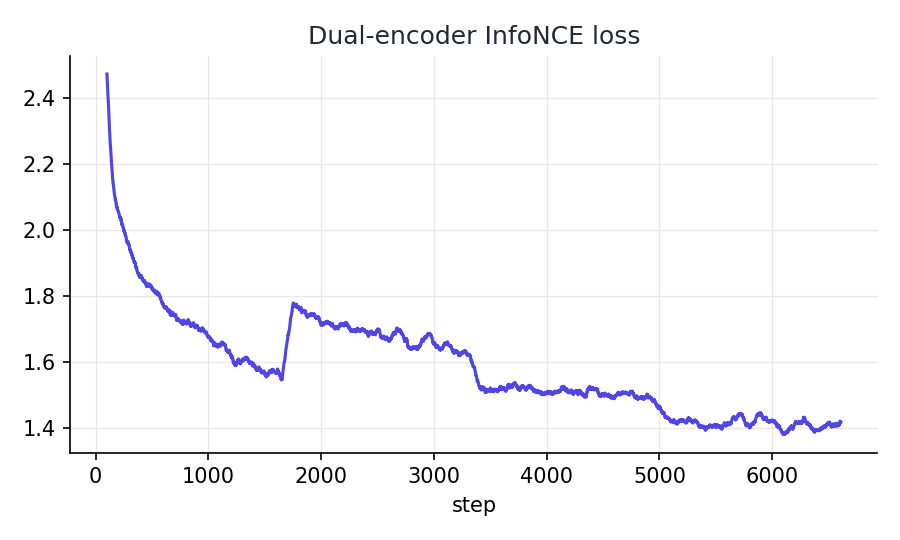

CPU times: user 1h 49min 25s, sys: 19min 35s, total: 2h 9min 1s
Wall time: 1h 38min 49s


In [19]:
%%time
P.stage_encoder()
if os.path.exists(P.p("fig_encoder_loss.png")):
    display(Image(P.p("fig_encoder_loss.png")))

## 3. Label bank and anchored per-label classifiers

In [20]:
%%time
P.stage_labelbank()
P.stage_classifier()

[labelbank] mode=centroid shape=(131073, 768)
  [classifier] mined 100 negatives/doc in 5s
  [classifier] epoch 1/10  bce 0.0836  scale 16.0  shift 0.719  29s
  [classifier] epoch 2/10  bce 0.0499  scale 19.1  shift 0.712  49s
  [classifier] epoch 3/10  bce 0.0356  scale 21.7  shift 0.717  69s
  [classifier] epoch 4/10  bce 0.0273  scale 23.4  shift 0.725  89s
  [classifier] epoch 5/10  bce 0.0221  scale 24.7  shift 0.734  109s
  [classifier] epoch 6/10  bce 0.0188  scale 25.5  shift 0.741  129s
  [classifier] epoch 7/10  bce 0.0167  scale 26.1  shift 0.749  149s
  [classifier] epoch 8/10  bce 0.0152  scale 26.4  shift 0.756  169s
  [classifier] epoch 9/10  bce 0.0142  scale 27.0  shift 0.762  189s
  [classifier] epoch 10/10  bce 0.0135  scale 27.1  shift 0.771  209s
[classifier] done in 210s
CPU times: user 3min 28s, sys: 5.69 s, total: 3min 34s
Wall time: 3min 34s


## 4. Conditional diffusion

  [diffusion] step 500/25000  loss 0.7240  mse 0.4961  nce 1.1395  51s
  [diffusion] step 1000/25000  loss 0.2698  mse 0.2329  nce 0.1841  101s
  [diffusion] step 1500/25000  loss 0.2265  mse 0.1958  nce 0.1537  152s
  [diffusion] step 2000/25000  loss 0.2049  mse 0.1770  nce 0.1396  203s
  [diffusion] step 2500/25000  loss 0.1909  mse 0.1646  nce 0.1314  253s
  [diffusion] step 3000/25000  loss 0.1814  mse 0.1563  nce 0.1257  304s
  [diffusion] step 3500/25000  loss 0.1741  mse 0.1497  nce 0.1219  355s
  [diffusion] step 4000/25000  loss 0.1683  mse 0.1446  nce 0.1185  405s
  [diffusion] step 4500/25000  loss 0.1634  mse 0.1403  nce 0.1157  456s
  [diffusion] step 5000/25000  loss 0.1595  mse 0.1367  nce 0.1139  506s
  [diffusion] step 5500/25000  loss 0.1559  mse 0.1336  nce 0.1119  557s
  [diffusion] step 6000/25000  loss 0.1529  mse 0.1308  nce 0.1105  608s
  [diffusion] step 6500/25000  loss 0.1498  mse 0.1280  nce 0.1090  658s
  [diffusion] step 7000/25000  loss 0.1472  mse 0.125

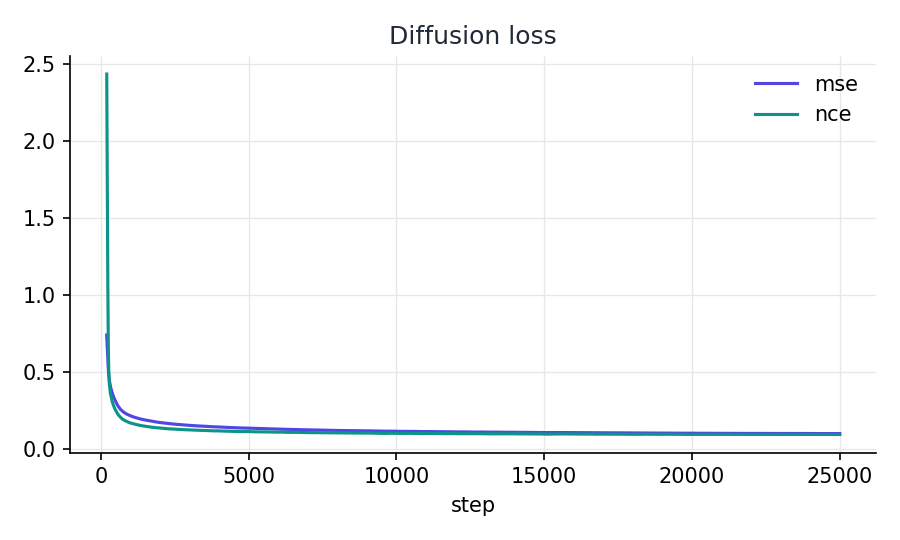

CPU times: user 42min 14s, sys: 2.65 s, total: 42min 17s
Wall time: 42min 15s


In [21]:
%%time
P.stage_diffusion()
display(Image(P.p("fig_diffusion_loss.png")))

## 5. Shortlists, rerankers, test evaluation

[shortlists] val: 17688 docs  diffusion 6.4s  retrieval 15.1s  diversity {'mean_pairwise_cos': 0.990173876285553, 'distinct_top1_labels': 1.34765625}
[shortlists] tst: 134835 docs  diffusion 48.8s  retrieval 115.1s  diversity {'mean_pairwise_cos': 0.9913236498832703, 'distinct_top1_labels': 1.28515625}
[shortlists] done in 207s
{
  "diffusion_s": 48.783557176589966,
  "retrieval_s": 115.07890200614929,
  "sample_diversity": {
    "mean_pairwise_cos": 0.9913236498832703,
    "distinct_top1_labels": 1.28515625
  }
}
  [reranker] epoch 10/40  listwise loss 2.9513
  [reranker] epoch 20/40  listwise loss 2.9388
  [reranker] epoch 30/40  listwise loss 2.9309
  [reranker] epoch 40/40  listwise loss 2.9355
  [reranker] epoch 10/40  listwise loss 1.9649
  [reranker] epoch 20/40  listwise loss 1.9552
  [reranker] epoch 30/40  listwise loss 1.9505
  [reranker] epoch 40/40  listwise loss 1.9457
  [reranker] epoch 10/40  listwise loss 2.9525
  [reranker] epoch 20/40  listwise loss 2.9421
  [reranke

## Test results

| Method | P@1 | P@3 | P@5 | nDCG@5 | PSP@1 | PSP@3 | PSP@5 | PSnDCG@5 | coverage@5 | R@300 |
|---|---|---|---|---|---|---|---|---|---|---|
| A0 dual encoder, 1 query (no diffusion) | 35.42 | 24.25 | 17.88 | 39.43 | 32.00 | 36.30 | 41.17 | 37.32 | 52.44 | 74.43 |
| A0 + anchored classifier | 34.99 | 23.51 | 16.95 | 37.77 | 27.47 | 32.35 | 36.69 | 32.96 | 46.77 | 74.43 |
| A0 + reranker | 39.20 | 26.38 | 19.17 | 42.63 | 31.93 | 37.49 | 42.72 | 38.46 | 53.21 | 74.43 |
| Diffusion only, 8 samples (vote) | 35.23 | 24.15 | 17.85 | 39.40 | 32.22 | 36.51 | 41.46 | 37.62 | 52.88 | 58.67 |
| Diffusion only, 8 samples + reranker | 39.05 | 26.20 | 18.97 | 42.33 | 31.92 | 37.53 | 42.67 | 38.47 | 53.36 | 58.67 |
| Doc + diffusion union + reranker (main) | 39.24 | 26.45 | 19.21 | 42.76 | 32.50 | 37.98 | 43.15 | 38.96 | 53.83 | 74.46 |
| Main + tail boost (tau=0.2) | 38.88 | 26.31 | 19.10 | 42.54 | 33.16 | 38.35 | 43.41 | 39.34 | 54.50 | 74.46 |

## Recall@5 by label-frequency bucket

| Method | unseen (0) | 1-2 | 3-5 | 6-20 | >20 |
|---|---|---|---|---|---|
| A0 dual encoder, 1 query (no diffusion) | 32.78 | 36.94 | 43.82 | 42.79 | 48.15 |
| A0 + anchored classifier | 10.29 | 27.51 | 38.59 | 43.33 | 58.48 |
| A0 + reranker | 42.56 | 35.79 | 43.48 | 47.23 | 61.39 |
| Diffusion only, 8 samples (vote) | 34.84 | 38.03 | 44.29 | 42.27 | 46.13 |
| Diffusion only, 8 samples + reranker | 42.72 | 36.72 | 43.48 | 46.35 | 58.64 |
| Doc + diffusion union + reranker (main) | 44.98 | 37.37 | 43.49 | 46.95 | 59.89 |
| Main + tail boost (tau=0.2) | 47.14 | 38.76 | 43.98 | 46.12 | 56.70 |
| test pairs | 1943 | 67211 | 75750 | 102086 | 37756 |

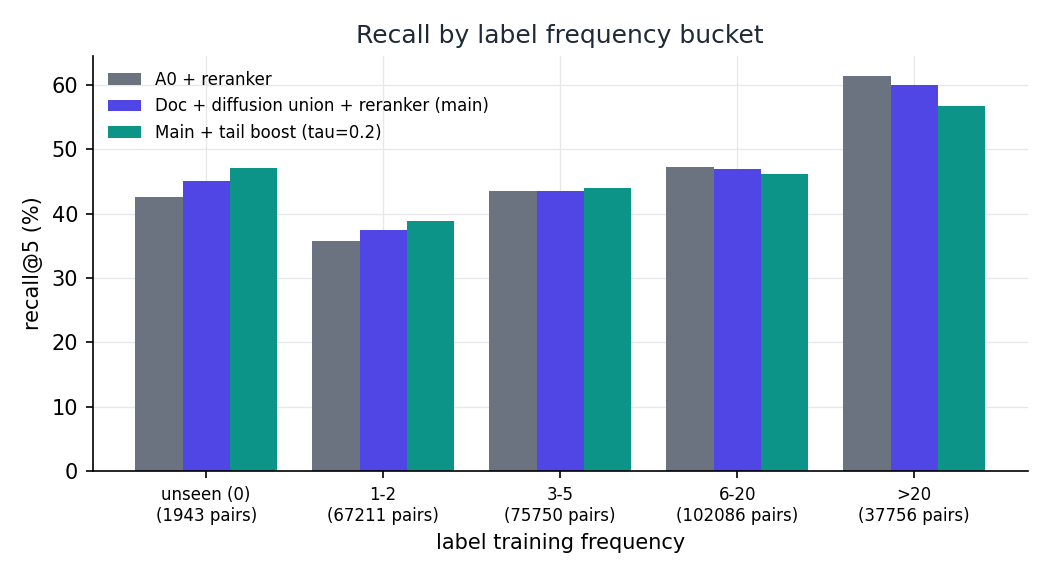

CPU times: user 4min 50s, sys: 32 s, total: 5min 22s
Wall time: 5min 19s


In [22]:
%%time
P.stage_shortlists()
print(open(P.p("shortlist_timing_tst.json")).read())
P.stage_rerank()
P.stage_evaluate()
display(Markdown(open(P.p("results.md")).read()))
display(Image(P.p("fig_bucket_recall.png")))

## 6. Efficiency

In [23]:
%%time
print(json.dumps(P.stage_efficiency(), indent=1))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[efficiency] {
 "num_labels": 131073,
 "n_docs_batched": 2000,
 "batched_ms_per_doc": {
  "encoder": 0.313413143157959,
  "diffusion": 0.3737986087799072,
  "retrieval": 0.3889181613922119,
  "rerank": 0.016989588737487793,
  "total": 1.093119502067566,
  "exhaustive_dot_all_labels": 0.06716442108154297
 },
 "single_doc_ms_hnsw": {
  "diffusion": 15.171318054199219,
  "search": 1.5982961654663086,
  "agg_rerank": 6.720619201660156,
  "total_excl_encoder": 23.490233421325684
 },
 "labels_touched_per_doc": {
  "ann_queries": 9,
  "per_query_k": 20,
  "reranked_candidates": 300,
  "fraction_of_vocab_scored_by_reranker": 0.002288800897209952
 },
 "params": {
  "encoder": 109482240,
  "diffusion": 34898432,
  "reranker": 4865,
  "classifier_delta_and_bias": 100795139,
  "label_bank_floats": 100664064,
  "one_vs_all_classifier_equivalent": 100795137
 },
 "peak_gpu_mem_MB": 5125.26513671875
}
{
 "num_labels": 131073,
 "n_docs_batched": 2000,
 "batched_ms_per_doc": {
  "encoder": 0.31341314315

## 7. v1 vs v3 comparison (needs the part-1 notebook output attached), report, artifacts

In [24]:
from xmcdiff.metrics import format_table
from xmcdiff.report import build

def compare_and_package():
    v1 = [p for p in glob.glob("/kaggle/input/**/run/results.json", recursive=True)]
    if v1:
        rows = {f"[v1 MiniLM] {k}": v for k, v in json.load(open(v1[0]))["test"].items()}
        rows.update({f"[v3] {k}": v for k, v in json.load(open(P.p("results.json")))["test"].items()})
        md_cmp = "## v1 (MiniLM, no hard negatives, no classifiers) vs v3\n\n" + format_table(rows)
        open(P.p("comparison.md"), "w").write(md_cmp)
        display(Markdown(md_cmp))
    else:
        print("part-1 output not attached: skipping the v1 vs v3 table")
    print(build(cfg.out_dir))
    keep = ["config.json", "encoder", "label_bank.npy", "labels.txt", "label_freq.npy", "inv_prop.npy", "diffusion.pt",
            "classifier.pt", "reranker_doc.pt", "reranker_a0.pt", "reranker_nodoc.pt", "hnsw.index", "test_examples.json",
            "stats.json", "results.json", "results.md", "ablations.json", "ablations.md", "efficiency.json",
            "comparison.md", "shortlist_timing_tst.json", "REPORT_DRAFT.md"]
    stage = "/kaggle/working/artifacts_v3"
    shutil.rmtree(stage, ignore_errors=True); os.makedirs(stage)
    for k in keep + [os.path.basename(f) for f in glob.glob(P.p("fig_*.png"))]:
        src = P.p(k)
        if os.path.isdir(src): shutil.copytree(src, os.path.join(stage, k))
        elif os.path.exists(src): shutil.copy(src, stage)
    shutil.make_archive("/kaggle/working/xmc_artifacts_v3", "zip", stage)
    shutil.make_archive("/kaggle/working/xmcdiff_code", "zip", "/kaggle/working", "xmcdiff")
    print("artifacts:", round(os.path.getsize("/kaggle/working/xmc_artifacts_v3.zip") / 2**20), "MB")

compare_and_package()

part-1 output not attached: skipping the v1 vs v3 table
/kaggle/working/run_v3/REPORT_DRAFT.md
artifacts: 1373 MB


## 8. Ablations on the held-out validation half (saved results above are safe if this runs out of time)

[ablation] n_samples=1: samples-only P@5 20.69  union R@300 76.70  P@5(rr) 22.32  PSP@5(rr) 47.55  div {'mean_pairwise_cos': 1.0, 'distinct_top1_labels': 1.0}
[ablation] n_samples=4: samples-only P@5 20.69  union R@300 76.69  P@5(rr) 22.46  PSP@5(rr) 47.88  div {'mean_pairwise_cos': 0.9916629195213318, 'distinct_top1_labels': 1.1953125}
[ablation] n_samples=8: samples-only P@5 20.72  union R@300 76.69  P@5(rr) 22.44  PSP@5(rr) 47.83  div {'mean_pairwise_cos': 0.9913270473480225, 'distinct_top1_labels': 1.29296875}
[ablation] n_samples=16: samples-only P@5 20.73  union R@300 76.71  P@5(rr) 22.45  PSP@5(rr) 47.89  div {'mean_pairwise_cos': 0.9915128946304321, 'distinct_top1_labels': 1.3515625}
[ablation] n_samples=32: samples-only P@5 20.72  union R@300 76.71  P@5(rr) 22.45  PSP@5(rr) 47.90  div {'mean_pairwise_cos': 0.991557776927948, 'distinct_top1_labels': 1.4296875}
[ablation] ddim_steps=2: samples-only P@5 20.27  union R@300 76.68  P@5(rr) 22.24  PSP@5(rr) 47.24  div {'mean_pairwise

Reference A0 (dual encoder, no diffusion) on the same 8844 validation half B docs: R@300 76.69, P@1 39.81, P@5 20.81, PSP@5 45.28; with reranker P@1 44.58, P@5 22.37, PSP@5 47.38.

## Inference-time ablations (validation half B split)

| Setting | samples-only P@1 | samples-only P@5 | samples-only PSP@5 | union R@300 | P@1 rr | P@5 rr | PSP@5 rr | distinct top-1 / S |
|---|---|---|---|---|---|---|---|---|
| n_samples=1 | 38.89 | 20.69 | 45.31 | 76.70 | 44.48 | 22.32 | 47.55 | 1.00 |
| n_samples=4 | 38.76 | 20.69 | 45.32 | 76.69 | 44.58 | 22.46 | 47.88 | 1.20 |
| n_samples=8 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.83 | 1.29 |
| n_samples=16 | 38.79 | 20.73 | 45.39 | 76.71 | 44.44 | 22.45 | 47.89 | 1.35 |
| n_samples=32 | 38.74 | 20.72 | 45.34 | 76.71 | 44.44 | 22.45 | 47.90 | 1.43 |
| ddim_steps=2 | 38.40 | 20.27 | 43.73 | 76.68 | 44.03 | 22.24 | 47.24 | 1.36 |
| ddim_steps=5 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.84 | 1.29 |
| ddim_steps=10 | 39.01 | 20.72 | 45.55 | 76.69 | 44.63 | 22.43 | 47.84 | 1.05 |
| ddim_steps=20 | 38.85 | 20.70 | 45.48 | 76.69 | 44.56 | 22.46 | 47.91 | 1.03 |
| guidance=0.0 | 38.63 | 20.25 | 43.20 | 76.69 | 43.80 | 22.15 | 47.04 | 2.58 |
| guidance=0.5 | 39.17 | 20.62 | 44.82 | 76.73 | 44.47 | 22.37 | 47.69 | 1.66 |
| guidance=1.0 | 39.09 | 20.75 | 45.42 | 76.73 | 44.54 | 22.44 | 47.88 | 1.25 |
| guidance=2.0 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.83 | 1.29 |
| guidance=4.0 | 35.28 | 18.77 | 40.75 | 76.75 | 43.91 | 22.06 | 46.59 | 2.85 |
| eta=0.0 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.84 | 1.29 |
| eta=1.0 | 38.75 | 20.61 | 45.12 | 76.73 | 44.57 | 22.42 | 47.88 | 1.69 |
| clamp_sphere=True | 38.76 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.84 | 1.29 |
| clamp_sphere=False | 39.01 | 20.57 | 45.09 | 76.72 | 44.57 | 22.38 | 47.75 | 1.27 |
| doc_budget=0.25 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.83 | 1.29 |
| doc_budget=0.5 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.83 | 1.29 |
| doc_budget=0.75 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.84 | 1.29 |
| tail_tau=0.0 | 38.75 | 20.72 | 45.39 | 76.69 | 44.53 | 22.44 | 47.83 | 1.29 |
| tail_tau=0.2 | 38.75 | 20.72 | 45.39 | 76.69 | 44.34 | 22.33 | 48.09 | 1.29 |
| tail_tau=0.5 | 38.76 | 20.72 | 45.39 | 76.69 | 42.05 | 21.81 | 47.77 | 1.29 |
| tail_tau=1.0 | 38.76 | 20.72 | 45.39 | 76.69 | 38.50 | 20.42 | 46.16 | 1.29 |

## Training-time ablations (6000 diffusion steps each)

| Variant | samples-only P@1 | P@5 | PSP@1 | PSP@5 | coverage@5 | samples R@300 | union R@300 |
|---|---|---|---|---|---|---|---|
| reference | 37.26 | 19.85 | 35.81 | 44.15 | 44.96 | 61.28 | 76.81 |
| no_infonce_anchor | 38.56 | 20.24 | 36.33 | 44.39 | 45.78 | 61.50 | 76.72 |
| beta=0 | 36.64 | 19.30 | 35.14 | 43.01 | 43.81 | 60.86 | 76.77 |
| beta=0.5 | 37.20 | 19.62 | 35.70 | 43.61 | 44.35 | 61.14 | 76.79 |
| adaln_conditioning | 35.82 | 19.09 | 33.28 | 41.69 | 42.97 | 59.78 | 76.71 |
| no_cfg_dropout | 38.83 | 19.99 | 34.67 | 42.50 | 44.71 | 63.17 | 76.66 |
| label_bank=text | 44.50 | 18.65 | 44.36 | 42.97 | 42.72 | 58.80 | 73.25 |
| label_bank=fused | 47.54 | 21.30 | 46.67 | 48.02 | 48.52 | 63.78 | 78.37 |

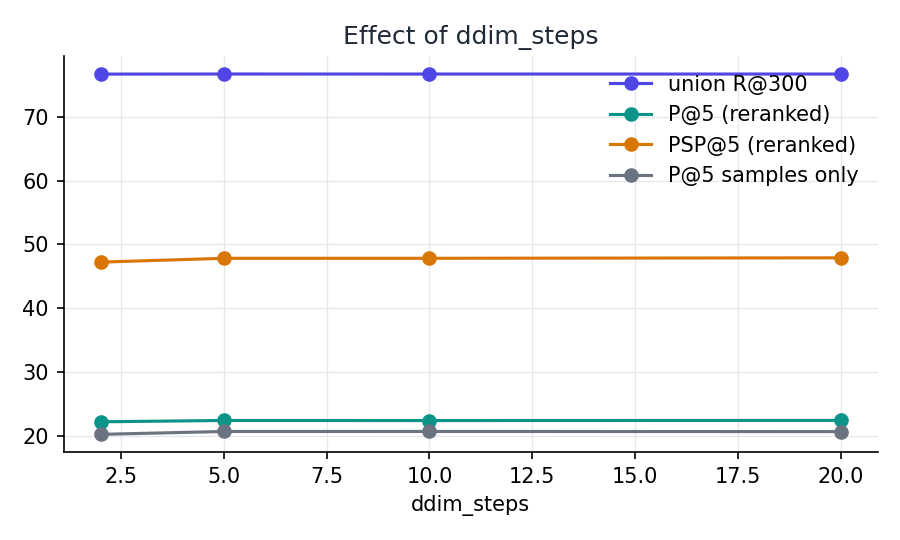

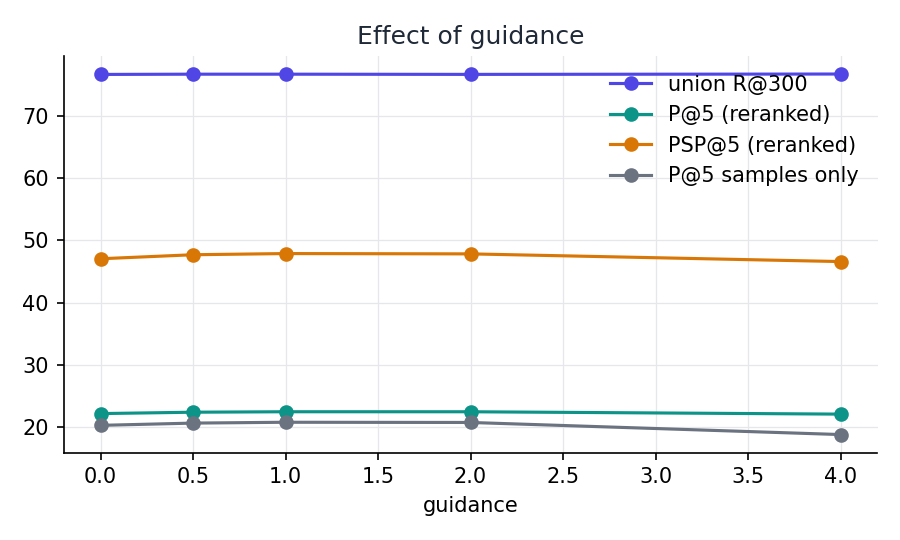

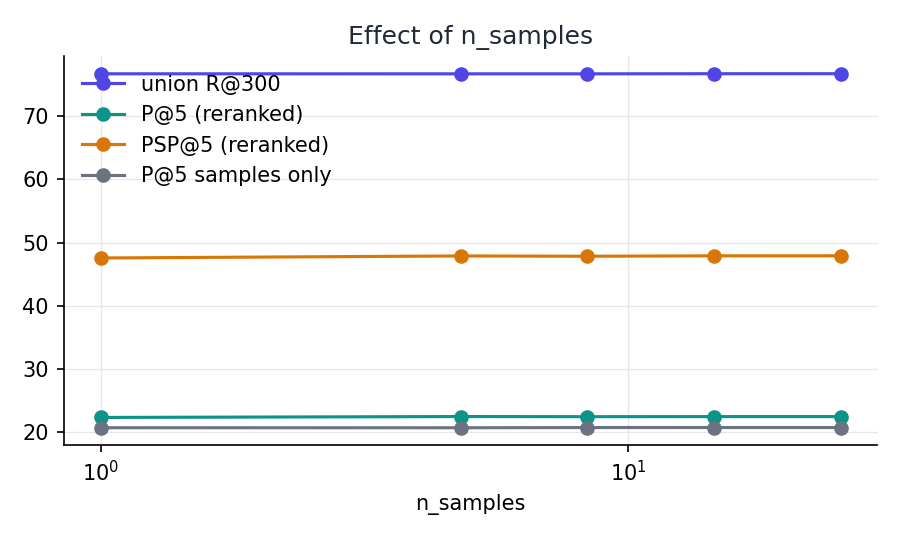

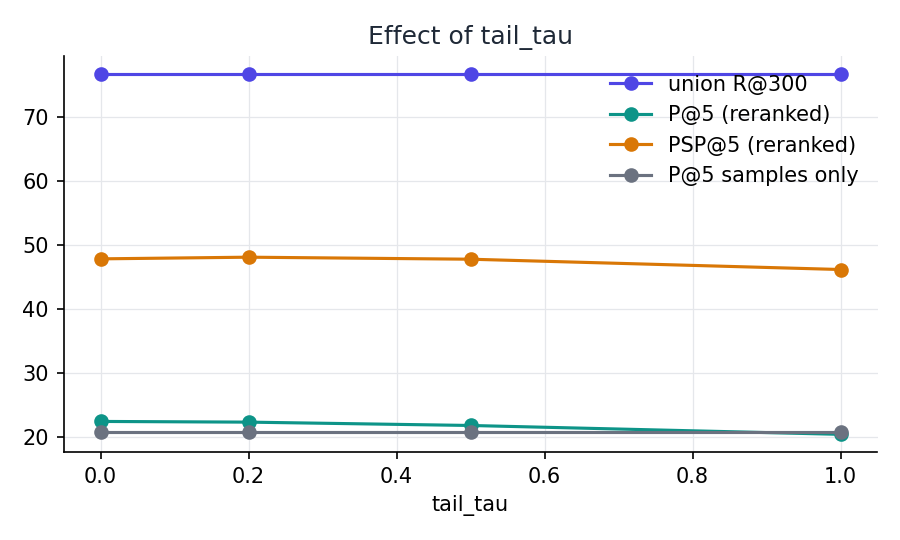

part-1 output not attached: skipping the v1 vs v3 table
/kaggle/working/run_v3/REPORT_DRAFT.md
artifacts: 1374 MB
CPU times: user 1h 26min 15s, sys: 13.2 s, total: 1h 26min 28s
Wall time: 1h 26min 18s


In [25]:
%%time
if RUN_ABLATIONS_INFERENCE:
    P.stage_ablations(training=False)
if RUN_ABLATIONS_TRAINING:
    P.stage_ablations(inference=False, train_steps=ABLATION_TRAIN_STEPS)
if os.path.exists(P.p("ablations.md")):
    display(Markdown(open(P.p("ablations.md")).read()))
for f in sorted(glob.glob(P.p("fig_sweep_*.png"))):
    display(Image(f))
compare_and_package()          # refresh report + artifacts with the ablations

## 9. Interface

In [26]:
if LAUNCH_APP:
    from xmcdiff.app import Predictor, build_ui
    pred = Predictor(cfg.out_dir)
    demo = build_ui(pred)
    demo.launch(share=True)